# TEP: Pre-training Enhanced Transformer for Multivariate Time Series Anomaly Detection

Implementation of the two-stage **unsupervised** framework from *Wang et al., "Pre-training
Enhanced Transformer for multivariate time series anomaly detection"*, Information Fusion
121 (2025).

## The method, in one paragraph

TEP reconstructs each point of a multivariate time series and flags a point as anomalous
when its reconstruction error is unusually large. Reconstruction happens in two stages: a
**pre-training stage** (Section 4.1) where **CANets** learns generic, segment-level context
from raw windows; and a **reconstruction stage** (Section 4.2) where a downstream
**Transformer** reconstructs each point using both the raw window and CANets' frozen
representation. At inference time (Section 4.3), reconstruction errors are re-weighted by a
hand-crafted **Anomaly Feature Knowledge** term (Eq. 20) and thresholded with **POT**
(Peaks-Over-Threshold) to produce the final 0/1 decision.

## What changed in this revision (v13) — structure, not behaviour

This revision reorganizes the notebook around **one config object and no duplicated code**,
and fills in four analyses from the paper that v12 didn't reproduce. Nothing about the core
math changed; every "PAPER GAP" assumption documented in v12 is carried over unchanged (see
the last section).

1. **`TEPConfig`** (Section 0) centralizes every hyperparameter — `M`, `k`, `N`, `num_layers`,
   `L`, `lr`, `batch_size`, `epochs_pretrain`, `epochs_recon`, POT `risk` — that used to be
   passed as separate keyword arguments to `CANets`, `ReconstructionTransformer`,
   `pretrain_canets`, `train_reconstruction`, `run_pipeline`, `run_pipeline_ablation`, ...
   Every function below takes one `cfg: TEPConfig` instead. Sweeping a parameter (Fig. 7)
   is now `cfg.with_(N=3)`, not four separately-maintained call sites.
2. **`train_loop`** (Section 3b-4b) is the ONE generic training routine (DataLoader + AdamW +
   epoch loop + logging), shared by CANets, the Reconstruction Transformer, and TranADLite.
   `pretrain_canets` / `train_reconstruction` / `train_tranad_lite` each only supply a
   `loss_fn(model, batch)` closure — the ~40 lines of loop boilerplate that used to be
   duplicated across two functions now exist once.
3. **Smoke tests moved to one section** (Section 12, `run_all_smoke_tests()`) instead of being
   interleaved after every class/function — library code and test code no longer alternate
   line by line.
4. **Four analyses from the paper that v12 didn't implement are added**, all built on the same
   `TEPConfig` / pipeline functions as everything else:
   - Section 8 — CANets convolutional-kernel heatmaps (Section 5.4, **Fig. 5**)
   - Section 9 — parameter sensitivity sweep over `N`, `num_layers`, `L` (Section 5.6, **Fig. 7**)
   - Section 10 — Gaussian-noise robustness study (Section 5.6, **Fig. 8, Fig. 9**)
   - Section 11 — Anomaly Feature Knowledge applied to an independent reconstruction model,
     `TranADLite` (Section 5.5, **Table 3**) — see that section's markdown cell for exactly how
     `TranADLite` simplifies the real TranAD [23], and why.

## Unsupervised — so why do the datasets have label files?

Section 5.1 is explicit: *"the training set of all datasets is unlabeled, whereas the test set
is labeled."* Concretely:

- **Training** (CANets pre-training + Transformer reconstruction) uses only MSE reconstruction
  loss (Eq. 12, Eq. 17) — no labels exist or are used at this stage.
- **Thresholding** (POT, Algorithm 3) is fit directly on the test set's own anomaly-score
  distribution — a statistical rule, not a labeled one.
- **Test labels are used in exactly one module**: `build_07_metrics` (Section 6), to score the
  model's already-made 0/1 predictions with Precision/Recall/F1/AUC. They never touch training
  or thresholding.

## Notebook structure — one section per paper component

| # | Section | Paper reference |
|---|---|---|
| 0 | `TEPConfig` — all hyperparameters in one place | Section 5.2 (implementation details) |
| 1 | Data: per-entity normalization & windowing | Section 3.2, Eq. (2)-(5) |
| 2 | Shared building blocks: Multi-Head Attention, TCE Block | Eq. (6)-(10) |
| 3-4 | CANets & Reconstruction Transformer (model definitions) | Section 4.1-4.2, Eq. (8)-(17) |
| 3b-4b | Training: one shared `train_loop`, model-specific loss closures | Algorithm 1-2 |
| 5 | Anomaly Feature Knowledge + POT | Section 4.3, Algorithm 3, Eq. (18)-(21) |
| 6 | Metrics: Precision / Recall / F1 / AUC / F1_blind | Section 5.2 |
| 7 | Full pipeline (`run_pipeline`, ablation) | Sections 4-5, end to end for one entity |
| 8 | CANets kernel visualization | Section 5.4, **Fig. 5** |
| 9 | Parameter sensitivity sweep | Section 5.6, **Fig. 7** |
| 10 | Gaussian-noise robustness study | Section 5.6, **Fig. 8, Fig. 9** |
| 11 | Knowledge generalization to TranADLite | Section 5.5, **Table 3** |
| 12 | Smoke tests (all of them, run together) | -- |
| 13 | Demo runs (pipeline, ablation, all four new analyses) | end to end, reduced epochs |

## Two implementation rules that are *not* stated as equations in the paper

**Rule 1 — everything is computed per-entity.** A dataset such as SMD has several independent
entities (e.g. 28 machines). Min/max normalization, sliding windows, and the POT threshold must
*never* mix data across entities.

**Rule 2 — hyperparameters the paper leaves unspecified are called out where they appear**,
most notably the POT risk level `q`, the kernel size of TCEBlock's projection/downsampling
convolutions, and the exact set of SMD machines/seeds used for the paper's reported averages.
Look for `PAPER GAP` in the code; the full list is repeated in the last markdown cell.

Reproducing the paper's exact numbers still requires downloading SMD / MSL / PSM, running on
every entity used in the paper, and using `epochs_pretrain=100, epochs_recon=10`
(`TEPConfig`'s defaults). All demo runs below use tiny epoch counts purely to verify the code
runs end to end quickly.

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab -- set the TEP_DATA_ROOT env var instead

## Imports & global setup

In [2]:
import os
import math
import random
import warnings
from dataclasses import dataclass, field, replace
from typing import Callable, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genpareto
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset


warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 0. Configuration

Section 0 -- Configuration
==========================
Every hyperparameter used anywhere in the pipeline (model sizes, training
schedule, decision-stage constants) lives in ONE place: `TEPConfig`. Every
function below takes a `cfg: TEPConfig` instead of five to ten separate
keyword arguments, so sweeping a parameter (e.g. Section 5.6 / Fig. 7's
N, num_layers, L sweep) means changing one field, not several call sites.

Paper cross-reference for each field is given inline. Fields marked
"PAPER GAP" are not given a numeric value anywhere in the paper; the default
here is this notebook's own documented choice (see markdown cells).

In [ ]:
# import os
# from dataclasses import dataclass, field, replace
# from typing import Optional


# Per-dataset feature dimension M and anomaly-knowledge window L.
# L values are the ones reported in Section 5.2 ("PSM, MSL and SMD datasets,
# with different abnormal sliding window sizes L employed: 70, 70 and 40").
DATASET_META = {
    "SMD": {"dim": 38, "L": 40},
    "MSL": {"dim": 55, "L": 70},
    "PSM": {"dim": 25, "L": 70},
}

# import os
# from dataclasses import dataclass, field, replace
# from typing import Optional


# Per-dataset feature dimension M and anomaly-knowledge window L.
# L values are the ones reported in Section 5.2 ("PSM, MSL and SMD datasets,
# with different abnormal sliding window sizes L employed: 70, 70 and 40").
DATASET_META = {
    "SMD": {"dim": 38, "L": 40},
    "MSL": {"dim": 55, "L": 70},
    "PSM": {"dim": 25, "L": 70},
}

DEFAULT_DATA_ROOT = os.environ.get(
    "TEP_DATA_ROOT", os.environ.get("DATA_ROOT", "./data")
)


@dataclass
class TEPConfig:
    """All hyperparameters for one TEP run on one entity."""

    # --- data / dataset (Section 5.1, Table 2) ---
    dataset: str = "SMD"
    M: int = 38                      # feature dimension; set from DATASET_META at load time
    k: int = 10                      # sliding window size (Section 5.2: "k is fixed to 10")

    # --- CANets / pre-training stage (Section 4.1, Algorithm 1) ---
    N: int = 2                       # number of TCE + Multi-Head Attention block pairs
    canets_dropout: float = 0.1
    epochs_pretrain: int = 100       # Section 5.2: "pre-training model is trained for 100 epochs"

    # --- Reconstruction Transformer (Section 4.2, Algorithm 2) ---
    num_layers: int = 4              # Section 5.2: "numbers of Encoder and Decoder ... set to 4"
    recon_dropout: float = 0.1
    epochs_recon: int = 10           # Section 5.2: "downstream transformer model are trained for 10 epochs"

    # --- optimizer (Section 5.2: "AdamW optimizer ... initial learning rate of 0.0001") ---
    lr: float = 1e-4
    batch_size: int = 128            # Section 5.2: "batch size b is established at 128"

    # --- decision stage / Anomaly Feature Knowledge (Section 4.3, Algorithm 3, Eq. 20-21) ---
    L: int = 40                      # abnormal sliding window size; dataset-specific, see DATASET_META
    pot_risk: float = 1e-3           # PAPER GAP: POT significance level q, never given a value in the paper
    pot_init_level: float = 0.98     # initial high quantile used to select GPD tail exceedances

    # --- misc ---
    seed: int = 0
    verbose: bool = True

    @property
    def num_heads(self) -> int:
        """Section 5.2: 'quantity of heads h ... set to correspond to the feature dimension M'."""
        return self.M

    @property
    def embed_dim(self) -> int:
        """CANets / Reconstruction Transformer both operate in R^{2M} (Eq. 9, Eq. 13)."""
        return 2 * self.M

    @classmethod
    def for_dataset(cls, dataset: str, **overrides) -> "TEPConfig":
        """Build a config pre-filled with a dataset's M and L from DATASET_META."""
        dataset = dataset.upper()
        meta = DATASET_META[dataset]
        cfg = cls(dataset=dataset, M=meta["dim"], L=meta["L"])
        return replace(cfg, **overrides) if overrides else cfg

    def with_(self, **overrides) -> "TEPConfig":
        """Return a copy with some fields overridden -- used heavily by the sensitivity sweeps."""
        return replace(self, **overrides)


@dataclass
class TEPConfig:
    """All hyperparameters for one TEP run on one entity."""

    # --- data / dataset (Section 5.1, Table 2) ---
    dataset: str = "SMD"
    M: int = 38                      # feature dimension; set from DATASET_META at load time
    k: int = 10                      # sliding window size (Section 5.2: "k is fixed to 10")

    # --- CANets / pre-training stage (Section 4.1, Algorithm 1) ---
    N: int = 2                       # number of TCE + Multi-Head Attention block pairs
    canets_dropout: float = 0.1
    epochs_pretrain: int = 100       # Section 5.2: "pre-training model is trained for 100 epochs"

    # --- Reconstruction Transformer (Section 4.2, Algorithm 2) ---
    num_layers: int = 4              # Section 5.2: "numbers of Encoder and Decoder ... set to 4"
    recon_dropout: float = 0.1
    epochs_recon: int = 10           # Section 5.2: "downstream transformer model are trained for 10 epochs"

    # --- optimizer (Section 5.2: "AdamW optimizer ... initial learning rate of 0.0001") ---
    lr: float = 1e-4
    batch_size: int = 128            # Section 5.2: "batch size b is established at 128"

    # --- decision stage / Anomaly Feature Knowledge (Section 4.3, Algorithm 3, Eq. 20-21) ---
    L: int = 40                      # abnormal sliding window size; dataset-specific, see DATASET_META
    pot_risk: float = 1e-3           # PAPER GAP: POT significance level q, never given a value in the paper
    pot_init_level: float = 0.98     # initial high quantile used to select GPD tail exceedances

    # --- misc ---
    seed: int = 0
    verbose: bool = True

    @property
    def num_heads(self) -> int:
        """Section 5.2: 'quantity of heads h ... set to correspond to the feature dimension M'."""
        return self.M

    @property
    def embed_dim(self) -> int:
        """CANets / Reconstruction Transformer both operate in R^{2M} (Eq. 9, Eq. 13)."""
        return 2 * self.M

    @classmethod
    def for_dataset(cls, dataset: str, **overrides) -> "TEPConfig":
        """Build a config pre-filled with a dataset's M and L from DATASET_META."""
        dataset = dataset.upper()
        meta = DATASET_META[dataset]
        cfg = cls(dataset=dataset, M=meta["dim"], L=meta["L"])
        return replace(cfg, **overrides) if overrides else cfg

    def with_(self, **overrides) -> "TEPConfig":
        """Return a copy with some fields overridden -- used heavily by the sensitivity sweeps."""
        return replace(self, **overrides)

## 1. Data

Section 1 -- Data: per-entity normalization & windowing (Section 3.2, Eq. 2-5)
================================================================================
Rule kept from the original notebook and still enforced here: EVERYTHING is
computed per-entity. Min/max normalization, sliding windows and (later) the
POT threshold must never mix two entities' data -- each is derived only from
that one entity's own train split.

In [4]:
# import os
# import numpy as np
# import pandas as pd
# from dataclasses import dataclass
# from typing import Tuple


GAMMA = 1e-8  # Eq. (2): small constant preventing division by zero


@dataclass
class Entity:
    """Raw train/test arrays + test labels for ONE independent entity (e.g. one SMD machine)."""
    name: str
    dataset: str
    train_raw: np.ndarray    # (T_train, M)
    test_raw: np.ndarray     # (T_test, M)
    test_labels: np.ndarray  # (T_test,) binary 0/1


def normalize_per_entity(entity: Entity, gamma: float = GAMMA) -> Tuple[np.ndarray, np.ndarray]:
    """
    Eq. (2): eta_t = (x_t - min(X)) / (max(X) - min(X) + gamma), using min/max
    computed ONLY from this entity's train split. Test values are clipped to
    [0, 1] since test min/max can fall outside the train range.
    """
    train, test = entity.train_raw, entity.test_raw
    mn = train.min(axis=0, keepdims=True)
    mx = train.max(axis=0, keepdims=True)
    denom = (mx - mn) + gamma

    train_norm = np.clip((train - mn) / denom, 0.0, 1.0)
    test_norm = np.clip((test - mn) / denom, 0.0, 1.0)
    return train_norm.astype(np.float32), test_norm.astype(np.float32)


def make_windows(data: np.ndarray, k: int, stride: int = 1, pad_repeat_first: bool = True) -> np.ndarray:
    """
    Eq. (4)-(5): sliding windows of length k over a SINGLE entity's (T, M) array.
    Padding repeats the first point (k - 1) times, so window[t, -1] == data[t]
    for every original time step t (the paper: "missing data points are ...
    filled in by inserting k - t occurrences of eta_1"). Fully vectorized.

    Returns (T, k, M) if pad_repeat_first else (T - k + 1, k, M).
    """
    assert data.ndim == 2, "make_windows expects a single entity's (T, M) array"

    if pad_repeat_first:
        pad = np.repeat(data[:1], k - 1, axis=0)
        padded = np.concatenate([pad, data], axis=0)
    else:
        padded = data

    windows = np.lib.stride_tricks.sliding_window_view(padded, window_shape=k, axis=0)  # (n, M, k)
    windows = windows[::stride].transpose(0, 2, 1)  # (n, k, M)
    return windows.astype(np.float32)


# --------------------------------------------------------------------------- #
# Loading real datasets (SMD / MSL / PSM) with a synthetic fallback so the
# notebook always runs end-to-end even without the real files present.
# --------------------------------------------------------------------------- #

def load_entity(dataset: str, entity_name: str, data_root: str = DEFAULT_DATA_ROOT) -> Entity:
    """Loads one entity's raw arrays from disk, in each dataset's native format."""
    dataset = dataset.upper()
    root = os.path.join(data_root, dataset)

    if dataset == "SMD":
        train_raw = np.loadtxt(os.path.join(root, "train", f"{entity_name}.txt"), delimiter=",")
        test_raw = np.loadtxt(os.path.join(root, "test", f"{entity_name}.txt"), delimiter=",")
        test_labels = np.loadtxt(os.path.join(root, "test_label", f"{entity_name}.txt"), delimiter=",")

    elif dataset == "MSL":
        train_raw = np.load(os.path.join(root, "MSL_train.npy"))
        test_raw = np.load(os.path.join(root, "MSL_test.npy"))
        test_labels = np.load(os.path.join(root, "MSL_test_label.npy"))

    elif dataset == "PSM":
        train_df = pd.read_csv(os.path.join(root, "train.csv"))
        test_df = pd.read_csv(os.path.join(root, "test.csv"))
        label_df = pd.read_csv(os.path.join(root, "test_label.csv"))
        drop_cols = lambda df: [c for c in df.columns
                                 if c.lower().startswith("timestamp")
                                 or c.lower().startswith("time")
                                 or c.lower().startswith("unnamed")]
        train_raw = train_df.drop(columns=drop_cols(train_df)).values
        test_raw = test_df.drop(columns=drop_cols(test_df)).values
        test_labels = label_df.iloc[:, -1].values

        expected_dim = DATASET_META["PSM"]["dim"]
        if train_raw.shape[1] != expected_dim:
            kept_cols = [c for c in train_df.columns if c not in drop_cols(train_df)]
            raise ValueError(
                f"PSM: expected {expected_dim} feature columns after dropping "
                f"{drop_cols(train_df)}, but got {train_raw.shape[1]}. "
                f"Columns kept: {kept_cols}"
            )
    else:
        raise ValueError(f"Unknown dataset: {dataset}")

    train_raw = np.nan_to_num(train_raw.astype(np.float32))
    test_raw = np.nan_to_num(test_raw.astype(np.float32))
    test_labels = test_labels.astype(np.int64).reshape(-1)
    return Entity(name=entity_name, dataset=dataset, train_raw=train_raw, test_raw=test_raw, test_labels=test_labels)


def make_synthetic_entity(dataset: str, entity_name: str = "synthetic-1", seed: int = 0) -> Entity:
    """Fallback synthetic entity (periodic signal + injected anomaly bursts), used only
    when the real dataset files aren't found under `data_root` -- keeps the notebook
    runnable end-to-end for architecture/logic verification without the real data."""
    rng = np.random.RandomState(seed)
    M = DATASET_META[dataset]["dim"]
    T_train, T_test = 2000, 1000

    t_train = np.linspace(0, 40 * np.pi, T_train)
    t_test = np.linspace(0, 20 * np.pi, T_test)
    freqs = rng.uniform(0.5, 1.5, size=M)
    phases = rng.uniform(0, 2 * np.pi, size=M)

    train_raw = np.stack([np.sin(freqs[j] * t_train + phases[j]) for j in range(M)], axis=1)
    train_raw += rng.normal(0, 0.05, size=train_raw.shape)

    test_raw = np.stack([np.sin(freqs[j] * t_test + phases[j]) for j in range(M)], axis=1)
    test_raw += rng.normal(0, 0.05, size=test_raw.shape)

    test_labels = np.zeros(T_test, dtype=np.int64)
    for _ in range(5):
        start = rng.randint(0, T_test - 30)
        length = rng.randint(10, 25)
        test_raw[start:start + length] += rng.normal(3.0, 0.5, size=(length, M))
        test_labels[start:start + length] = 1

    return Entity(name=entity_name, dataset=dataset,
                  train_raw=train_raw.astype(np.float32), test_raw=test_raw.astype(np.float32),
                  test_labels=test_labels)


def get_entity(dataset: str, entity_name: str, data_root: str = DEFAULT_DATA_ROOT) -> Entity:
    """Loads real data if present under `data_root`, otherwise falls back to a synthetic entity."""
    try:
        ent = load_entity(dataset, entity_name, data_root)
        print(f"[data] loaded real data for {dataset}/{entity_name} from {data_root}")
        return ent
    except (FileNotFoundError, OSError) as e:
        print(f"[data] real data not found under {data_root} ({e}).")
        print(f"[data] falling back to a synthetic entity for {dataset}/{entity_name}.")
        print(f"[data] to reproduce paper results, download {dataset} and place it under {data_root}.")
        return make_synthetic_entity(dataset, entity_name)

## 2. Shared building blocks

Section 2 -- Shared building blocks (Eq. 6-7, Eq. 8-10)
=========================================================
Multi-Head Attention (used both inside CANets and the Reconstruction
Transformer) and the TCE Block (CANets-only). Kept in one place since both
downstream models (Section 3, Section 4) import them.

In [5]:
#import math
#from typing import Optional

#import torch
#import torch.nn as nn


class PositionalEncoding(nn.Module):
    """Standard sinusoidal positional encoding (paper's PE function, Section 4.1), batch-first.

    BUG FIX (found while running on MSL/PSM, whose feature dim M is odd -- 55 and 25): the
    original pe[:, 1::2] = cos(...) assignment used the full div_term, but when embed_dim is
    odd, the 1::2 slice has one FEWER column than 0::2 (e.g. embed_dim=55 -> 28 sin columns,
    27 cos columns) while div_term always has ceil(embed_dim/2) entries, so the two column
    counts mismatched and torch raised a shape error. CANets/ReconstructionTransformer always
    call this with embed_dim = 2*M (even), so the bug was invisible until TranADLite's PE(cfg.M)
    was actually exercised on an odd-M dataset -- which the original single-dataset (SMD-only)
    demo cells never did. Fixed by truncating div_term to the cosine slice's actual width.
    """

    def __init__(self, embed_dim: int, max_len: int = 512):
        super().__init__()
        pe = torch.zeros(max_len, embed_dim)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, embed_dim, 2, dtype=torch.float32) * (-math.log(10000.0) / embed_dim))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[: pe[:, 1::2].shape[1]])
        self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, embed_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x + self.pe[:, : x.size(1)]


class Swish(nn.Module):
    """x * sigmoid(x), used after every BatchNorm inside TCEBlock (Eq. 10)."""

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x * torch.sigmoid(x)


class MultiHeadAttention(nn.Module):
    """Scaled dot-product multi-head self-/cross-attention (Eq. 6-7), batch-first: (batch, seq, embed_dim)."""

    def __init__(self, embed_dim: int, num_heads: int, dropout: float = 0.0):
        super().__init__()
        assert embed_dim % num_heads == 0, "embed_dim must be divisible by num_heads"
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads

        self.q_proj = nn.Linear(embed_dim, embed_dim)
        self.k_proj = nn.Linear(embed_dim, embed_dim)
        self.v_proj = nn.Linear(embed_dim, embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def _split_heads(self, x: torch.Tensor) -> torch.Tensor:
        b, s, _ = x.shape
        return x.view(b, s, self.num_heads, self.head_dim).permute(0, 2, 1, 3)  # (b, h, s, d)

    def forward(self, query: torch.Tensor, key: Optional[torch.Tensor] = None,
                value: Optional[torch.Tensor] = None) -> torch.Tensor:
        key = query if key is None else key
        value = key if value is None else value

        b, sq, _ = query.shape
        q = self._split_heads(self.q_proj(query))
        k = self._split_heads(self.k_proj(key))
        v = self._split_heads(self.v_proj(value))

        scores = torch.matmul(q, k.transpose(-2, -1)) / (self.head_dim ** 0.5)  # Eq. (7): QK^T / sqrt(d_k)
        attn = self.dropout(torch.softmax(scores, dim=-1))

        out = torch.matmul(attn, v).permute(0, 2, 1, 3).reshape(b, sq, self.embed_dim)
        return self.out_proj(out)


class MultiHeadAttentionBlock(nn.Module):
    """
    The "Multi-Head Attention Block" box in Fig. 2 (left): a residual + LayerNorm
    ("Add & Norm") wrapper around MultiHeadAttention. Alternated N times with
    TCEBlock inside CANets, per Eq. (11): P1 = TCE(MultiHead(TCE(MultiHead(I0)))).
    """

    def __init__(self, embed_dim: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        self.attn = MultiHeadAttention(embed_dim, num_heads, dropout=dropout)
        self.norm = nn.LayerNorm(embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.norm(x + self.dropout(self.attn(x)))


class TCEBlock(nn.Module):
    """
    Temporal Context Extraction block, Eq. (10):

        I1 = Conv1d_0(I0)                                  projection layer
        I2 = Swish(BatchNorm(Conv1d_1(I1)))                 upsampling layer (temporal, kernel = k-1)
        I3 = LayerNorm(I2 + Linear(LReLU(Linear(I2))))       feedforward + Add & Norm
        I4 = Swish(BatchNorm(Conv1d_2(I3)))                 downsampling layer
        I5 = I3 + Dropout(Swish(I1 + I4))                    final residual

    All intermediate representations stay at embed_dim = 2M channels, matching
    the paper's stated shape I_i^0 in R^{k x b x 2M}.

    PAPER GAP: Eq. (10) has no LayerNorm term in either residual, but Fig. 2's
    diagram shows explicit "Add & Norm" boxes. We follow the figure (and standard
    Transformer/Conformer practice) and keep LayerNorm after the feedforward step.

    PAPER GAP: only the upsampling conv's kernel (k - 1) is given a numeric value.
    The projection (Conv1d_0) and downsampling (Conv1d_2) convs never get one;
    `proj_kernel_size` / `down_kernel_size` default to 1 (pointwise), since the
    paper describes them as reshaping/aggregating steps, not temporal mixing --
    both are now explicit, named constructor arguments instead of hardcoded.
    """

    def __init__(self, embed_dim: int, seq_len: int, ffn_expansion: int = 2, dropout: float = 0.1,
                 proj_kernel_size: int = 1, down_kernel_size: int = 1):
        super().__init__()
        self.proj_conv = nn.Conv1d(embed_dim, embed_dim, kernel_size=proj_kernel_size,
                                    padding=proj_kernel_size // 2)

        up_kernel = max(seq_len - 1, 1)  # k - 1, per the paper's stated kernel size
        self.up_conv = nn.Conv1d(embed_dim, embed_dim, kernel_size=up_kernel, padding=up_kernel // 2)
        self.up_bn = nn.BatchNorm1d(embed_dim)
        self.swish_up = Swish()

        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * ffn_expansion),
            nn.LeakyReLU(0.1),
            nn.Linear(embed_dim * ffn_expansion, embed_dim),
        )
        self.ffn_norm = nn.LayerNorm(embed_dim)

        self.down_conv = nn.Conv1d(embed_dim, embed_dim, kernel_size=down_kernel_size,
                                    padding=down_kernel_size // 2)
        self.down_bn = nn.BatchNorm1d(embed_dim)
        self.swish_down = Swish()

        self.swish_merge = Swish()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (batch, seq_len, embed_dim) == I_0^0
        seq_len = x.size(1)
        x_t = x.transpose(1, 2)  # channel-first for Conv1d: (batch, embed_dim, seq_len)

        i1 = self.proj_conv(x_t)[:, :, :seq_len]                    # I1^0, channel-first
        i2 = self.up_conv(i1)[:, :, :seq_len]                         # guard off-by-one from padding
        i2 = self.swish_up(self.up_bn(i2)).transpose(1, 2)              # I2^0, back to (batch, seq, embed)

        i3 = self.ffn_norm(i2 + self.ffn(i2))                            # I3^0

        i4 = self.down_conv(i3.transpose(1, 2))[:, :, :seq_len]            # I4^0, channel-first
        i4 = self.swish_down(self.down_bn(i4)).transpose(1, 2)              # back to (batch, seq, embed)

        i1 = i1.transpose(1, 2)                                               # I1^0 back to (batch, seq, embed)
        return i3 + self.dropout(self.swish_merge(i1 + i4))                   # I5^0

## 3-4. CANets & Reconstruction Transformer

Section 3 -- CANets (Algorithm 1, Eq. 8-12) and
Section 4 -- Reconstruction Transformer (Algorithm 2, Eq. 13-17)
==================================================================
Both models take a `TEPConfig` instead of separate M/k/N/num_layers/dropout
arguments, so their sizes always stay in sync with whatever config a given
run/sweep is using.

In [6]:
#import torch
#import torch.nn as nn
#import torch.nn.functional as F


class CANets(nn.Module):
    """
    Algorithm 1: I' (raw window, M dims) is concatenated with zeros to reach 2M
    dims (Eq. 9), positionally encoded, passed through N alternating pairs of
    MultiHeadAttentionBlock + TCEBlock (Eq. 11), then projected back to M dims
    with Linear + Sigmoid (Eq. 12's target: reconstruct I').
    """

    def __init__(self, cfg: TEPConfig):
        super().__init__()
        self.cfg = cfg
        self.pos_enc = PositionalEncoding(cfg.embed_dim, max_len=cfg.k + 8)

        self.mha_blocks = nn.ModuleList([
            MultiHeadAttentionBlock(cfg.embed_dim, cfg.num_heads, dropout=cfg.canets_dropout)
            for _ in range(cfg.N)
        ])
        self.tce_blocks = nn.ModuleList([
            TCEBlock(cfg.embed_dim, seq_len=cfg.k, dropout=cfg.canets_dropout)
            for _ in range(cfg.N)
        ])
        self.out_proj = nn.Linear(cfg.embed_dim, cfg.M)

    def forward(self, I_prime: torch.Tensor) -> torch.Tensor:
        # I_prime: (batch, k, M)
        zeros = torch.zeros_like(I_prime)
        I0 = torch.cat([I_prime, zeros], dim=-1)   # Eq. (9): (batch, k, 2M)
        x = self.pos_enc(I0)
        for mha, tce in zip(self.mha_blocks, self.tce_blocks):
            x = mha(x)
            x = tce(x)
        return torch.sigmoid(self.out_proj(x))       # P: (batch, k, M)


class ZeroCANets(nn.Module):
    """
    Ablation stand-in for a pretrained CANets model (Table 4's "no CANets" rows).
    Same forward(I_prime) -> P interface as CANets, but always returns zeros,
    i.e. "no segment-level representation at all".
    """

    def forward(self, I_prime: torch.Tensor) -> torch.Tensor:
        return torch.zeros_like(I_prime)


def leaky_relu_activation(x: torch.Tensor) -> torch.Tensor:
    """LeakyReLU(0.1), matching Eq. (14)'s LReLU (PyTorch's TransformerEncoderLayer default is ReLU)."""
    return F.leaky_relu(x, negative_slope=0.1)


class DecoderBlock(nn.Module):
    """
    One decoder block, Eq. (15), with LayerNorm ("Add & Norm") after every
    residual sub-layer -- the paper's decoder builds on the standard Transformer
    (Vaswani et al. [3]), which normalizes after each residual; Eq. (15) itself
    omits the norm terms symbolically, the same way Eq. (10) does for TCEBlock.

        I_1^2 = Norm(I_0^2 + Dropout(MultiHeadAttn(I_0^2, I_0^2, I_0^2)))     self-attention
        I_2^2 = Norm(I_1^2 + Dropout(MultiHeadAttn(I_1^2, memory, memory)))    cross-attention
        I_3^2 = Norm(I_2^2 + Linear(LReLU(Linear(I_2^2))))                     feedforward
    """

    def __init__(self, embed_dim: int, num_heads: int, dropout: float = 0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(embed_dim, num_heads, dropout=dropout)
        self.cross_attn = MultiHeadAttention(embed_dim, num_heads, dropout=dropout)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.norm3 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.LeakyReLU(0.1),
            nn.Linear(embed_dim * 2, embed_dim),
        )

    def forward(self, tgt: torch.Tensor, memory: torch.Tensor) -> torch.Tensor:
        tgt = self.norm1(tgt + self.dropout1(self.self_attn(tgt, tgt, tgt)))
        tgt = self.norm2(tgt + self.dropout2(self.cross_attn(tgt, memory, memory)))
        tgt = self.norm3(tgt + self.ffn(tgt))
        return tgt


class ReconstructionTransformer(nn.Module):
    """
    Algorithm 2, Eq. (13)-(16):
      I1 = PE(Concat(I', P))                    -> encoder input, (batch, k, 2M)
      memory = TransformerEncoder(I1)            -> cfg.num_layers stacked encoder layers
      e_t = I'[-1]                                -> last raw point of the window, (batch, M)
      I_0^2 = Concat(e_t, e_t)                     -> single decoder token, (batch, 1, 2M)
                                                       (Eq. 15: literal duplication, not a learned projection)
      I_3^2 = cfg.num_layers stacked DecoderBlocks(I_0^2, memory)
      R = Sigmoid(Linear(I_3^2))                    -> reconstructed e_t, (batch, M)
    """

    def __init__(self, cfg: TEPConfig):
        super().__init__()
        self.cfg = cfg
        self.pos_enc = PositionalEncoding(cfg.embed_dim, max_len=cfg.k + 8)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=cfg.embed_dim, nhead=cfg.num_heads, dim_feedforward=cfg.embed_dim * 4,
            dropout=cfg.recon_dropout, batch_first=True, activation=leaky_relu_activation,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=cfg.num_layers)

        self.decoder_blocks = nn.ModuleList([
            DecoderBlock(cfg.embed_dim, num_heads=cfg.num_heads, dropout=cfg.recon_dropout)
            for _ in range(cfg.num_layers)
        ])
        self.out_proj = nn.Linear(cfg.embed_dim, cfg.M)

    def forward(self, I_prime: torch.Tensor, P: torch.Tensor) -> torch.Tensor:
        # I_prime, P: (batch, k, M)
        I1 = self.pos_enc(torch.cat([I_prime, P], dim=-1))   # Eq. (13): (batch, k, 2M)
        memory = self.encoder(I1)

        e_t = I_prime[:, -1, :]                                # (batch, M), last point only
        tgt = torch.cat([e_t, e_t], dim=-1).unsqueeze(1)         # Eq. (15): Concat(e_t, e_t), (batch, 1, 2M)

        for block in self.decoder_blocks:
            tgt = block(tgt, memory)

        return torch.sigmoid(self.out_proj(tgt)).squeeze(1)         # (batch, M)


class TranADLite(nn.Module):
    """
    A deliberately SIMPLIFIED stand-in for Tuli et al.'s TranAD [23], used only
    in Section 5.5's replication (Table 3: does Anomaly Feature Knowledge help a
    *different* reconstruction-based model, not just TEP?). The real TranAD uses
    a two-phase adversarial training scheme with two decoders; reproducing that
    exactly is out of scope here. TranADLite keeps only the property Section 5.5
    actually needs -- an independent, non-CANets, reconstruction-based
    Transformer autoencoder -- as a single-phase encoder/decoder Transformer
    over the raw window, with no adversarial loss and no pretrained
    segment-level representation.
    """

    def __init__(self, cfg: TEPConfig):
        super().__init__()
        self.cfg = cfg
        self.pos_enc = PositionalEncoding(cfg.M, max_len=cfg.k + 8)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=cfg.M, nhead=1, dim_feedforward=cfg.M * 4,
            dropout=cfg.recon_dropout, batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=2)
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=cfg.M, nhead=1, dim_feedforward=cfg.M * 4,
            dropout=cfg.recon_dropout, batch_first=True,
        )
        self.decoder = nn.TransformerDecoder(decoder_layer, num_layers=2)
        self.out_proj = nn.Linear(cfg.M, cfg.M)

    def forward(self, window: torch.Tensor) -> torch.Tensor:
        # window: (batch, k, M) -> reconstructs the whole window
        x = self.pos_enc(window)
        memory = self.encoder(x)
        out = self.decoder(x, memory)
        return torch.sigmoid(self.out_proj(out))  # (batch, k, M)

## 3b-4b. Training

Section 3b/4b -- Training
==========================
`train_loop` is the ONE generic training routine (DataLoader + AdamW + epoch
loop + logging) shared by CANets, the Reconstruction Transformer, and
TranADLite. Each model-specific `pretrain_*` / `train_*` function only
supplies what differs: how to compute the loss for one batch.

Section 5.2: "The AdamW optimizer is utilized, with an initial learning rate
of 0.0001." -- applies to every model trained in this notebook.

In [7]:
#from typing import Callable, Optional

#import numpy as np
#import torch
#import torch.nn as nn
#import torch.nn.functional as F
#from torch.utils.data import DataLoader, TensorDataset


def train_loop(model: nn.Module, windows: np.ndarray, cfg: TEPConfig, epochs: int,
                loss_fn: Callable[[nn.Module, torch.Tensor], torch.Tensor],
                device: torch.device, tag: str, verbose_every: Optional[int] = None) -> nn.Module:
    """
    Generic supervised-by-reconstruction training loop.

    `loss_fn(model, batch) -> scalar loss` encapsulates everything model-specific
    (which sub-modules to call, which target to compare against); everything else
    (batching, optimizer, logging) is identical across CANets / ReconstructionTransformer
    / TranADLite, so it lives here exactly once instead of being copy-pasted per model.
    """
    verbose_every = cfg.verbose * 10 if verbose_every is None else verbose_every
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr)

    loader = DataLoader(TensorDataset(torch.from_numpy(windows).float()),
                         batch_size=cfg.batch_size, shuffle=True, drop_last=False)

    model.train()
    for epoch in range(epochs):
        total_loss, n_batches = 0.0, 0
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model, batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            n_batches += 1
        if verbose_every and (epoch % verbose_every == 0 or epoch == epochs - 1):
            print(f"[{tag}] epoch {epoch + 1}/{epochs} loss={total_loss / n_batches:.6f}")

    model.eval()
    return model


def pretrain_canets(entity: Entity, train_windows: np.ndarray, cfg: TEPConfig, device: torch.device) -> CANets:
    """Algorithm 1: unsupervised pretraining of CANets on ONE entity's train windows.
    Loss = MSE(P, I') (Eq. 12). After training the model is frozen."""
    model = CANets(cfg)

    def loss_fn(m: CANets, batch: torch.Tensor) -> torch.Tensor:
        P = m(batch)
        return F.mse_loss(P, batch)

    model = train_loop(model, train_windows, cfg, cfg.epochs_pretrain, loss_fn, device,
                        tag=f"CANets pretrain/{entity.name}")
    for p in model.parameters():
        p.requires_grad_(False)
    return model


def train_reconstruction(canets: nn.Module, entity: Entity, train_windows: np.ndarray,
                          cfg: TEPConfig, device: torch.device) -> ReconstructionTransformer:
    """Algorithm 2: trains the downstream Transformer using the frozen CANets for P.
    Loss = MSE(R, e_t) (Eq. 17)."""
    canets = canets.to(device).eval()
    model = ReconstructionTransformer(cfg)

    def loss_fn(m: ReconstructionTransformer, batch: torch.Tensor) -> torch.Tensor:
        with torch.no_grad():
            P = canets(batch)
        target = batch[:, -1, :]
        pred = m(batch, P)
        return F.mse_loss(pred, target)

    return train_loop(model, train_windows, cfg, cfg.epochs_recon, loss_fn, device,
                       tag=f"Reconstruction train/{entity.name}")


def train_tranad_lite(entity: Entity, train_windows: np.ndarray, cfg: TEPConfig, device: torch.device) -> TranADLite:
    """Trains the simplified TranAD stand-in (Section 5.5 / Table 3 replication) on
    ONE entity's train windows, reconstructing the whole window with plain MSE."""
    model = TranADLite(cfg)

    def loss_fn(m: TranADLite, batch: torch.Tensor) -> torch.Tensor:
        recon = m(batch)
        return F.mse_loss(recon, batch)

    return train_loop(model, train_windows, cfg, cfg.epochs_recon, loss_fn, device,
                       tag=f"TranADLite train/{entity.name}")


@torch.no_grad()
def compute_reconstruction_errors(canets: nn.Module, recon_model: ReconstructionTransformer,
                                   windows: np.ndarray, device: torch.device, batch_size: int = 256) -> np.ndarray:
    """Per-point, per-dimension squared reconstruction error, shape (T, M),
    for windows of shape (T, k, M) where windows[t, -1] == raw x[t].

    PAPER GAP: Eq. (18) defines R_error as a single scalar (MSE averaged over all T' and M),
    but Algorithm 3 then sliding-windows that same R_error into T' per-timestamp pieces
    (Eq. 19) -- only possible if R_error is a (T', M) array, not a scalar. We keep the
    elementwise (never-reduced) array here, since that is what Algorithm 3 actually consumes;
    see the write-up in the closing 'Where the paper is ambiguous' cell (point 6).
    """
    canets.eval()
    recon_model.eval()
    x = torch.from_numpy(windows).float()
    errors = []
    for i in range(0, x.shape[0], batch_size):
        batch = x[i:i + batch_size].to(device)
        P = canets(batch)
        pred = recon_model(batch, P)
        target = batch[:, -1, :]
        errors.append(((pred - target) ** 2).cpu().numpy())
    return np.concatenate(errors, axis=0)


@torch.no_grad()
def compute_canets_only_errors(canets: CANets, windows: np.ndarray, device: torch.device,
                                batch_size: int = 256) -> np.ndarray:
    """Ablation helper (Table 4, 'no Transformer' row): use CANets' own reconstruction
    of the window's last time step as the prediction, with no downstream Transformer."""
    canets.eval()
    x = torch.from_numpy(windows).float()
    errors = []
    for i in range(0, x.shape[0], batch_size):
        batch = x[i:i + batch_size].to(device)
        pred = canets(batch)[:, -1, :]
        target = batch[:, -1, :]
        errors.append(((pred - target) ** 2).cpu().numpy())
    return np.concatenate(errors, axis=0)


@torch.no_grad()
def compute_tranad_lite_errors(model: TranADLite, windows: np.ndarray, device: torch.device,
                                batch_size: int = 256) -> np.ndarray:
    """Per-point, per-dimension squared error for TranADLite (Section 5.5 replication),
    taking the last time step of the reconstructed window."""
    model.eval()
    x = torch.from_numpy(windows).float()
    errors = []
    for i in range(0, x.shape[0], batch_size):
        batch = x[i:i + batch_size].to(device)
        recon = model(batch)
        pred, target = recon[:, -1, :], batch[:, -1, :]
        errors.append(((pred - target) ** 2).cpu().numpy())
    return np.concatenate(errors, axis=0)

## 5. Anomaly Feature Knowledge + POT

Section 5 -- Anomaly Feature Knowledge + POT (Section 4.3, Algorithm 3, Eq. 18-21)
=====================================================================================

In [8]:
#import math
#import numpy as np
#from scipy.stats import genpareto


def sliding_window_error(point_errors: np.ndarray, L: int) -> np.ndarray:
    """point_errors: (T, M) per-point per-dimension reconstruction error for ONE entity.
    Returns (T, L, M) sliding windows, padded by repeating the first error row, so
    window_error[t, -1] == point_errors[t]."""
    return make_windows(point_errors, k=L, pad_repeat_first=True)


def anomaly_feature_knowledge_score(point_errors: np.ndarray, L: int) -> np.ndarray:
    """
    Algorithm 3 / Eq. (20):
      window_error = sliding_window(point_errors, L)
      knowledge = softmax(sigmoid(window_error), dim=time) * L
      score = window_error * knowledge  -> take the last time step of each window

    Returns score of shape (T, M): one score per original point per dimension.
    Fully vectorized (no Python loop over time steps).

    L=0 is used by the Section 5.6 / Fig. 7 sweep to mean "no incorporation of
    Anomaly Feature Knowledge" (the paper's own definition of that sweep
    endpoint) -- in that case the raw per-point error is returned unchanged.
    """
    if L <= 0:
        return point_errors
    window_error = sliding_window_error(point_errors, L)                 # (T, L, M)
    sig = 1.0 / (1.0 + np.exp(-window_error))                              # sigmoid
    exp_sig = np.exp(sig - sig.max(axis=1, keepdims=True))                   # softmax over time axis, stable
    knowledge = (exp_sig / exp_sig.sum(axis=1, keepdims=True)) * L
    weighted = window_error * knowledge                                       # (T, L, M)
    return weighted[:, -1, :]                                                    # (T, M)


def pot_threshold(scores_for_threshold: np.ndarray, risk: float = 1e-3, init_level: float = 0.98) -> float:
    """
    Peaks-Over-Threshold extreme-value threshold (Siffer et al. [36]), fit on a FLAT
    1-D array of scores. Eq. (21): delta = POT(Score) is a SINGLE threshold computed
    once from the whole T'xM score matrix -- callers must pass `score.reshape(-1)`.

    PAPER GAP: `risk` (POT significance level q) is never given a numeric value in the
    paper; 1e-3 is this notebook's default (common in OmniAnomaly / TranAD / Anomaly
    Transformer), overridable via `TEPConfig.pot_risk`.
    """
    scores = np.asarray(scores_for_threshold).reshape(-1)
    init_th = np.quantile(scores, init_level)
    exceed = scores[scores > init_th] - init_th

    if len(exceed) < 10:
        return float(np.quantile(scores, 1 - risk / 10))  # not enough tail data for a reliable GPD fit

    try:
        xi, _loc, sigma = genpareto.fit(exceed, floc=0)
    except Exception:
        return float(np.quantile(scores, 1 - risk / 10))

    n, n_exceed = len(scores), len(exceed)
    if abs(xi) < 1e-6:
        return float(init_th - sigma * math.log(risk * n / n_exceed))
    return float(init_th + (sigma / xi) * (((risk * n / n_exceed) ** (-xi)) - 1))


def decide_anomalies(score: np.ndarray, threshold: float) -> np.ndarray:
    """Eq. (21): a point is anomalous if ANY dimension's score meets or exceeds the
    single global POT threshold delta. score: (T, M); threshold: scalar. Returns (T,)."""
    return (score >= threshold).any(axis=1).astype(np.int64)

## 6. Metrics

Section 6 -- Metrics: Precision / Recall / F1 / AUC / F1_blind (Section 5.2)
==============================================================================
This is the ONLY module that touches `entity.test_labels`.

In [9]:
#from typing import Dict
#import numpy as np
#from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score


def compute_prf(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, float]:
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


def compute_auc(y_true: np.ndarray, anomaly_score: np.ndarray) -> float:
    if len(np.unique(y_true)) < 2:
        return float("nan")
    return float(roc_auc_score(y_true, anomaly_score))


def compute_f1_blind(test_score: np.ndarray, test_labels: np.ndarray, risk: float = 1e-3) -> Dict[str, float]:
    """
    F1_blind (Abdulaal et al. [37], cited in Section 5.2): split the test set 40% / 60%.
    A SINGLE global POT threshold (Eq. 21) is fit on only the first 40% of test scores,
    flattened across all dimensions, and applied unchanged to the remaining 60%.
    """
    split = int(test_score.shape[0] * 0.4)
    calib_score, eval_score = test_score[:split], test_score[split:]
    eval_labels = test_labels[split:]

    threshold = pot_threshold(calib_score.reshape(-1), risk=risk)
    preds = decide_anomalies(eval_score, threshold)

    metrics = compute_prf(eval_labels, preds)
    metrics["auc"] = compute_auc(eval_labels, eval_score.max(axis=1))
    return metrics

## 7. Full pipeline

Section 7 -- Full pipeline (Sections 4-5, end to end, one entity at a time)
=============================================================================
Every run function below takes a single `TEPConfig` (plus `entity_name` /
`data_root` / `device`), instead of a long list of separate keyword
arguments. This is what makes the Section 9/10 sweeps (Fig. 5/7/8/9-style
analyses) a simple loop over `cfg.with_(...)` rather than duplicated code.

In [10]:
#import random
#from dataclasses import replace
#from typing import Dict, List, Optional, Tuple

#import numpy as np
#import pandas as pd
#import torch


def _seed_all(seed: Optional[int]) -> None:
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)


def prepare_entity(cfg: TEPConfig, entity_name: str, data_root: str) -> Tuple[Entity, np.ndarray, np.ndarray]:
    """Loads + normalizes + windows ONE entity. Shared by run_pipeline and run_pipeline_ablation
    so both always preprocess identically."""
    entity = get_entity(cfg.dataset, entity_name, data_root)
    train_norm, test_norm = normalize_per_entity(entity)
    train_windows = make_windows(train_norm, k=cfg.k)
    test_windows = make_windows(test_norm, k=cfg.k)
    return entity, train_windows, test_windows


def run_pipeline(cfg: TEPConfig, entity_name: str, data_root: str = DEFAULT_DATA_ROOT,
                  device: torch.device = torch.device("cpu"), seed: Optional[int] = None,
                  return_arrays: bool = False):
    """
    Full TEP pipeline for ONE entity:
      1-3. load, normalize, window (per-entity, Eq. 2-5)
      4. pretrain + freeze CANets (Algorithm 1)
      5. train the Reconstruction Transformer (Algorithm 2)
      6-8. reconstruction error -> Anomaly Feature Knowledge score -> single global
           POT threshold -> Precision/Recall/F1/AUC/F1_blind (Algorithm 3)

    NOTE ON BIAS: Algorithm 3 fits delta on the very test scores being scored, which
    makes the plain F1 optimistic. `F1_blind` (Section 5.2) calibrates on a held-out
    40% slice instead and is the fairer number for comparing architectures.
    """
    _seed_all(seed)
    entity, train_windows, test_windows = prepare_entity(cfg, entity_name, data_root)

    canets = pretrain_canets(entity, train_windows, cfg, device)
    recon_model = train_reconstruction(canets, entity, train_windows, cfg, device)

    test_point_errors = compute_reconstruction_errors(canets, recon_model, test_windows, device)
    test_score = anomaly_feature_knowledge_score(test_point_errors, L=cfg.L)

    threshold = pot_threshold(test_score.reshape(-1), risk=cfg.pot_risk, init_level=cfg.pot_init_level)
    preds = decide_anomalies(test_score, threshold)

    if cfg.verbose:
        print(f"[{entity.dataset}/{entity.name}] predicted positive rate: {preds.mean():.4f}  "
              f"| true positive rate: {entity.test_labels.mean():.4f}  | POT threshold: {threshold:.6f}")

    metrics = compute_prf(entity.test_labels, preds)
    metrics["auc"] = compute_auc(entity.test_labels, test_score.max(axis=1))
    for key, val in compute_f1_blind(test_score, entity.test_labels, risk=cfg.pot_risk).items():
        metrics[f"blind_{key}"] = val
    metrics["entity"], metrics["dataset"] = entity_name, cfg.dataset

    if return_arrays:
        arrays = {"entity": entity, "test_point_errors": test_point_errors,
                  "test_score": test_score, "threshold": threshold, "preds": preds}
        return metrics, arrays
    return metrics


def run_pipeline_multi_seed(cfg: TEPConfig, entity_name: str, seeds: List[int] = (0, 1, 2), **kwargs) -> pd.DataFrame:
    """Runs run_pipeline for the same entity/config under several seeds; returns one row per seed."""
    rows = []
    for s in seeds:
        row = run_pipeline(cfg, entity_name, seed=s, **kwargs)
        row["seed"] = s
        rows.append(row)
    return pd.DataFrame(rows)


def run_all_entities(cfg: TEPConfig, entity_names: List[str], **kwargs) -> pd.DataFrame:
    """Runs run_pipeline independently for each entity (e.g. all 28 SMD machines)."""
    return pd.DataFrame([run_pipeline(cfg, name, **kwargs) for name in entity_names])


# --------------------------------------------------------------------------- #
# Ablation study (Section 5.7, Table 4)
# --------------------------------------------------------------------------- #

def run_pipeline_ablation(cfg: TEPConfig, entity_name: str, data_root: str = DEFAULT_DATA_ROOT,
                           use_canets: bool = True, use_transformer: bool = True, use_knowledge: bool = True,
                           device: torch.device = torch.device("cpu"), seed: Optional[int] = None) -> Dict:
    """
    Same per-entity pipeline as run_pipeline, with three independent on/off switches
    reproducing Table 4's four rows:

        row 1 (CANets only)             : use_canets=True,  use_transformer=False, use_knowledge=False
        row 2 (Transformer + Knowledge) : use_canets=False, use_transformer=True,  use_knowledge=True
        row 3 (no Knowledge)            : use_canets=True,  use_transformer=True,  use_knowledge=False
        row 4 (full TEP)                : use_canets=True,  use_transformer=True,  use_knowledge=True
    """
    if not use_canets and not use_transformer:
        raise ValueError("use_canets=False and use_transformer=False together leave no model to "
                          "produce a reconstruction -- not one of the paper's Table 4 ablations.")

    _seed_all(seed)
    entity, train_windows, test_windows = prepare_entity(cfg, entity_name, data_root)

    if use_canets:
        canets = pretrain_canets(entity, train_windows, cfg, device)
    else:
        canets = ZeroCANets().to(device)

    if use_transformer:
        recon_model = train_reconstruction(canets, entity, train_windows, cfg, device)
        test_point_errors = compute_reconstruction_errors(canets, recon_model, test_windows, device)
    else:
        test_point_errors = compute_canets_only_errors(canets, test_windows, device)

    test_score = anomaly_feature_knowledge_score(test_point_errors, L=cfg.L) if use_knowledge else test_point_errors

    threshold = pot_threshold(test_score.reshape(-1), risk=cfg.pot_risk, init_level=cfg.pot_init_level)
    preds = decide_anomalies(test_score, threshold)

    if cfg.verbose:
        print(f"[ablation CANets={use_canets} Transformer={use_transformer} Knowledge={use_knowledge}] "
              f"predicted positive rate: {preds.mean():.4f}  | true positive rate: {entity.test_labels.mean():.4f}")

    metrics = compute_prf(entity.test_labels, preds)
    metrics["auc"] = compute_auc(entity.test_labels, test_score.max(axis=1))
    metrics.update(entity=entity_name, dataset=cfg.dataset,
                    CANets=use_canets, Transformer=use_transformer, Knowledge=use_knowledge)
    return metrics


DEFAULT_ABLATION_CONFIGS = [
    {"use_canets": True, "use_transformer": False, "use_knowledge": False},
    {"use_canets": False, "use_transformer": True, "use_knowledge": True},
    {"use_canets": True, "use_transformer": True, "use_knowledge": False},
    {"use_canets": True, "use_transformer": True, "use_knowledge": True},
]


def run_ablation_study(cfg: TEPConfig, entity_name: str,
                        configs: Optional[List[Dict[str, bool]]] = None, **kwargs) -> pd.DataFrame:
    """Runs run_pipeline_ablation once per configuration; defaults to the paper's Table 4 rows."""
    configs = DEFAULT_ABLATION_CONFIGS if configs is None else configs
    rows = [run_pipeline_ablation(cfg, entity_name, **c, **kwargs) for c in configs]
    df = pd.DataFrame(rows)
    ordered = ["CANets", "Transformer", "Knowledge", "precision", "recall", "f1", "auc", "entity", "dataset"]
    return df[[c for c in ordered if c in df.columns]]

## 8. CANets kernel visualization (Fig. 5)

Section 8 -- Analysis of CANets: convolutional kernel visualization (Section 5.4, Fig. 5)
=============================================================================================
Reproduces the paper's inspection of what CANets' TCE blocks learn: pull the
1D convolution kernels from shallow/middle/deep layers and plot them as
heatmaps of (feature dim x kernel position), same layout as Fig. 5.

In [11]:
#from typing import List

#import numpy as np
#import torch
#import matplotlib.pyplot as plt


def collect_conv_layers(canets: CANets) -> List[torch.nn.Conv1d]:
    """
    Returns every Conv1d inside CANets' TCE blocks, in forward-pass order
    (shallow -> deep), matching the paper's "randomly select three
    one-dimensional convolutional layers ... from shallow to deep".
    """
    layers = []
    for tce in canets.tce_blocks:
        layers.extend([tce.proj_conv, tce.up_conv, tce.down_conv])
    return layers


def plot_conv_kernel_heatmaps(canets: CANets, dims_to_plot: List[int] = (3, 6, 10, 20),
                               layer_indices: List[int] = None, figsize=(14, 8)):
    """
    Fig. 5-style visualization: for each selected layer (shallow/middle/deep) and
    each selected feature dimension, plot a heatmap of shape
    (out_channels_subset x kernel_size), where warmer colors = larger kernel
    weight magnitude ("importance"), matching the paper's description:
    "the element at row i and column j represents the importance of the jth
    timestamp data of the corresponding time series dimension i".

    `dims_to_plot` indexes into the conv's output-channel dimension (2M
    channels since CANets operates in embed_dim = 2M); indices are clipped to
    the layer's actual channel count so this also works on small smoke-test models.
    """
    layers = collect_conv_layers(canets)
    if layer_indices is None:
        n = len(layers)
        layer_indices = sorted(set([0, n // 2, n - 1]))  # shallow, middle, deep

    fig, axes = plt.subplots(1, len(layer_indices), figsize=figsize, squeeze=False)
    labels = ["Shallow layer", "Middle layer", "Deep layer"]

    for col, li in enumerate(layer_indices):
        conv = layers[li]
        weight = conv.weight.detach().cpu().numpy()   # (out_channels, in_channels, kernel_size)
        out_channels = weight.shape[0]
        dims = [d for d in dims_to_plot if d < out_channels] or [0]

        # For each selected output channel, take its kernel averaged over input
        # channels -> (kernel_size,); stack across selected dims -> (n_dims, kernel_size).
        heat = np.stack([weight[d].mean(axis=0) for d in dims], axis=0)

        ax = axes[0][col]
        im = ax.imshow(heat, aspect="auto", cmap="coolwarm")
        ax.set_title(labels[col] if col < len(labels) else f"Layer {li}")
        ax.set_xlabel("kernel position")
        ax.set_ylabel("feature dim")
        ax.set_yticks(range(len(dims)))
        ax.set_yticklabels(dims)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    fig.suptitle("CANets convolutional kernel weights by depth (paper Fig. 5)")
    plt.tight_layout()
    return fig

## 9. Parameter sensitivity (Fig. 7)

Section 9 -- Parameter sensitivity analysis (Section 5.6, Fig. 7)
=====================================================================
Sweeps N (TCE/MHA block repeats), num_layers (encoder/decoder depth) and L
(anomaly-knowledge window size), one at a time, holding the others at the
paper's reported best setting (N=2, num_layers=4, L=70 for MSL/PSM, 40 for
SMD). Because every hyperparameter now lives in `TEPConfig`, each sweep point
is just `cfg.with_(N=n)` -- no duplicated pipeline code.

In [12]:
#from typing import List, Optional

#import pandas as pd
#import torch
#import matplotlib.pyplot as plt


def sweep_parameter(cfg: TEPConfig, entity_name: str, param: str, values: List,
                     device: torch.device = torch.device("cpu"), **kwargs) -> pd.DataFrame:
    """Runs run_pipeline once per value of `param` (e.g. param='N', values=[1,2,3]),
    keeping every other TEPConfig field fixed. Returns one row per value."""
    rows = []
    for v in values:
        swept_cfg = cfg.with_(**{param: v})
        metrics = run_pipeline(swept_cfg, entity_name, device=device, **kwargs)
        metrics[param] = v
        rows.append(metrics)
    return pd.DataFrame(rows)


def parameter_sensitivity_study(cfg: TEPConfig, entity_name: str,
                                 N_values: List[int] = (1, 2, 3),
                                 num_layers_values: List[int] = (1, 2, 3, 4, 5),
                                 L_values: List[int] = (0, 40, 70, 100, 150),
                                 device: torch.device = torch.device("cpu"), **kwargs) -> dict:
    """
    Fig. 7's three sweeps: number of TCE blocks (N), number of Encoder/Decoder
    layers (num_layers), and abnormal sliding window size (L). L=0 means "no
    Anomaly Feature Knowledge" (score = raw reconstruction error), matching the
    paper's own definition of that endpoint.
    """
    results = {
        "N": sweep_parameter(cfg, entity_name, "N", list(N_values), device=device, **kwargs),
        "num_layers": sweep_parameter(cfg, entity_name, "num_layers", list(num_layers_values), device=device, **kwargs),
        "L": sweep_parameter(cfg, entity_name, "L", list(L_values), device=device, **kwargs),
    }
    return results


def plot_sensitivity_results(results: dict, metrics: List[str] = ("f1", "auc")):
    """Fig. 7-style 2-row x 3-col grid: one column per swept parameter, one row per metric."""
    params = list(results.keys())
    fig, axes = plt.subplots(len(metrics), len(params), figsize=(4 * len(params), 3.5 * len(metrics)), squeeze=False)

    for row, metric in enumerate(metrics):
        for col, param in enumerate(params):
            df = results[param].sort_values(param)
            ax = axes[row][col]
            ax.plot(df[param], df[metric], marker="o")
            ax.set_xlabel(param)
            ax.set_ylabel(metric.upper() if metric == "f1" else metric.upper())
            ax.set_title(f"{metric.upper()} vs {param}")

    plt.tight_layout()
    return fig

## 10. Robustness / Gaussian noise (Fig. 8-9)

Section 10 -- Robustness study: Gaussian white noise (Section 5.6, Fig. 8, Fig. 9)
======================================================================================
Adds Gaussian white noise at a given SNR (in dB) to the TRAINING split only
(the paper: "we introduce varying levels of Gaussian white noise in the
training set of MSL"), retrains the full pipeline on the noisy data, and
evaluates on the (clean) original test split.

In [13]:
#from typing import List

#import numpy as np
#import pandas as pd
#import torch
#import matplotlib.pyplot as plt


def add_gaussian_noise(x: np.ndarray, snr_db: float, rng: np.random.RandomState) -> np.ndarray:
    """Adds zero-mean Gaussian noise to `x` so that the resulting signal-to-noise
    ratio is approximately `snr_db` decibels: SNR_dB = 10 log10(P_signal / P_noise)."""
    signal_power = np.mean(x ** 2) + 1e-12
    noise_power = signal_power / (10 ** (snr_db / 10))
    noise = rng.normal(0, np.sqrt(noise_power), size=x.shape).astype(x.dtype)
    return x + noise


def run_pipeline_with_train_noise(cfg: TEPConfig, entity_name: str, snr_db: float,
                                   data_root: str, device: torch.device, seed: int = 0) -> dict:
    """Same as run_pipeline, but Gaussian noise at `snr_db` is injected into the
    (already min-max-normalized) TRAINING windows before CANets/Transformer training;
    evaluation stays on the clean test split, per Section 5.6's robustness protocol."""
    _seed_all(seed)
    rng = np.random.RandomState(seed)

    entity, train_windows, test_windows = prepare_entity(cfg, entity_name, data_root)
    train_windows = add_gaussian_noise(train_windows, snr_db, rng)

    canets = pretrain_canets(entity, train_windows, cfg, device)
    recon_model = train_reconstruction(canets, entity, train_windows, cfg, device)

    test_point_errors = compute_reconstruction_errors(canets, recon_model, test_windows, device)
    test_score = anomaly_feature_knowledge_score(test_point_errors, L=cfg.L)
    threshold = pot_threshold(test_score.reshape(-1), risk=cfg.pot_risk, init_level=cfg.pot_init_level)
    preds = decide_anomalies(test_score, threshold)

    metrics = compute_prf(entity.test_labels, preds)
    metrics["auc"] = compute_auc(entity.test_labels, test_score.max(axis=1))
    metrics["snr_db"] = snr_db
    metrics["entity"], metrics["dataset"] = entity_name, cfg.dataset
    return metrics


def robustness_study(cfg: TEPConfig, entity_name: str, snr_values_db: List[float],
                      data_root: str, device: torch.device = torch.device("cpu"), seed: int = 0) -> pd.DataFrame:
    """Fig. 8: F1 across a range of Gaussian-noise SNR levels (10 dB to 100 dB in the paper)."""
    rows = [run_pipeline_with_train_noise(cfg, entity_name, snr, data_root, device, seed) for snr in snr_values_db]
    return pd.DataFrame(rows)


def plot_noisy_sequence(entity: Entity, dim: int, snr_values_db: List[float], seed: int = 0,
                         n_points: int = 300, figsize=(13, 3)):
    """Fig. 9-style plot: original vs. noisy training signal at several SNR levels, one dimension."""
    rng = np.random.RandomState(seed)
    original = entity.train_raw[:n_points, dim]

    fig, axes = plt.subplots(1, len(snr_values_db), figsize=figsize, sharey=True)
    if len(snr_values_db) == 1:
        axes = [axes]
    for ax, snr in zip(axes, snr_values_db):
        noisy = add_gaussian_noise(original, snr, rng)
        ax.plot(original, color="black", linewidth=0.8, label="Original Data")
        ax.plot(noisy, color="tab:red", linewidth=0.8, alpha=0.8, label=f"Noisy Data (SNR {snr:g}dB)")
        ax.set_title(f"SNR {snr:g}dB")
        ax.set_xlabel("Timestamp")
        ax.legend(fontsize=8)
    axes[0].set_ylabel("Value")
    plt.tight_layout()
    return fig


def plot_robustness_curve(df: pd.DataFrame, metric: str = "f1", figsize=(7, 4)):
    """Fig. 8-style curve: metric vs. SNR (dB)."""
    df = df.sort_values("snr_db")
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot(df["snr_db"], df[metric], marker="o", color="tab:red", label=f"{metric.upper()} with noise")
    ax.axhline(df[metric].iloc[-1], linestyle="--", color="gray", label=f"{metric.upper()} without noise (ref.)")
    ax.set_xlabel("SNR (dB)")
    ax.set_ylabel(metric.upper())
    ax.set_title(f"{metric.upper()} score under Gaussian noise (paper Fig. 8)")
    ax.legend()
    plt.tight_layout()
    return fig

## 11. Knowledge generalization to TranADLite (Table 3)

Section 11 -- Universality of Anomaly Feature Knowledge (Section 5.5, Table 3)
==================================================================================
Tests whether Anomaly Feature Knowledge (Eq. 20) helps a DIFFERENT
reconstruction-based model, not just TEP -- using TranADLite (see
`build_04_models.TranADLite` docstring for exactly how it simplifies the real
TranAD, and why).

In [14]:
#from typing import Optional

#import pandas as pd
#import torch


def run_tranad_lite_pipeline(cfg: TEPConfig, entity_name: str, data_root: str,
                              use_knowledge: bool, device: torch.device = torch.device("cpu"),
                              seed: Optional[int] = None) -> dict:
    """TranADLite reconstruction + (optionally) Anomaly Feature Knowledge re-weighting,
    mirroring Table 3's 'TranAD' vs 'TranAD with Knowledge' rows."""
    _seed_all(seed)
    entity, train_windows, test_windows = prepare_entity(cfg, entity_name, data_root)

    model = train_tranad_lite(entity, train_windows, cfg, device)
    test_point_errors = compute_tranad_lite_errors(model, test_windows, device)

    test_score = anomaly_feature_knowledge_score(test_point_errors, L=cfg.L) if use_knowledge else test_point_errors
    threshold = pot_threshold(test_score.reshape(-1), risk=cfg.pot_risk, init_level=cfg.pot_init_level)
    preds = decide_anomalies(test_score, threshold)

    metrics = compute_prf(entity.test_labels, preds)
    metrics["auc"] = compute_auc(entity.test_labels, test_score.max(axis=1))
    metrics.update(entity=entity_name, dataset=cfg.dataset, knowledge=use_knowledge)
    return metrics


def knowledge_generalization_study(cfg: TEPConfig, entity_name: str, data_root: str,
                                    device: torch.device = torch.device("cpu"), seed: int = 0) -> pd.DataFrame:
    """Table 3: TranADLite F1 with vs. without Anomaly Feature Knowledge, same entity/config."""
    rows = [
        run_tranad_lite_pipeline(cfg, entity_name, data_root, use_knowledge=False, device=device, seed=seed),
        run_tranad_lite_pipeline(cfg, entity_name, data_root, use_knowledge=True, device=device, seed=seed),
    ]
    df = pd.DataFrame(rows)
    df["method"] = df["knowledge"].map({False: "TranADLite", True: "TranADLite with Knowledge"})
    return df[["method", "precision", "recall", "f1", "auc", "entity", "dataset"]]

## 12. Smoke tests

Section 12 -- Smoke tests
===========================
All correctness checks live here, in ONE place, instead of being interleaved
with the library code above. Run `run_all_smoke_tests()` once after loading
everything; a bug in any module is caught before it can silently affect
downstream sections.

In [15]:
#import numpy as np
#import torch
#from sklearn.metrics import f1_score


def test_normalize_and_window_no_leak():
    """normalize_per_entity / make_windows must never mix two entities' data (Rule 1)."""
    rng = np.random.RandomState(0)
    k = 5

    a_train = rng.uniform(0, 1, size=(20, 3)).astype(np.float32)
    ent_a = Entity("A", "toy", a_train, rng.uniform(0, 1, size=(10, 3)).astype(np.float32), np.zeros(10))
    b_train = rng.uniform(100, 200, size=(20, 3)).astype(np.float32)
    ent_b = Entity("B", "toy", b_train, rng.uniform(100, 200, size=(10, 3)).astype(np.float32), np.zeros(10))

    a_train_n, _ = normalize_per_entity(ent_a)
    b_train_n, _ = normalize_per_entity(ent_b)
    assert 0.0 <= a_train_n.min() and a_train_n.max() <= 1.0
    assert 0.0 <= b_train_n.min() and b_train_n.max() <= 1.0

    concat_train = np.concatenate([a_train, b_train], axis=0)
    global_mn, global_mx = concat_train.min(axis=0, keepdims=True), concat_train.max(axis=0, keepdims=True)
    a_train_wrong = (a_train - global_mn) / (global_mx - global_mn + GAMMA)
    assert a_train_wrong.max() < 0.05, "global normalization should crush entity A into a tiny range"
    assert a_train_n.max() > a_train_wrong.max()

    win_a_raw = make_windows(a_train, k=k)
    assert win_a_raw.shape == (20, k, 3) and win_a_raw.max() < 10

    concat_raw = np.concatenate([a_train, b_train], axis=0)
    leak_window = make_windows(concat_raw, k=k)[20]  # window straddling the entity boundary
    assert leak_window.max() > 50 and leak_window.min() < 10, \
        "expected the naive-concatenation window to mix entity A's and B's value scales"
    print("PASS: normalize_per_entity / make_windows do not leak across entity boundaries.")


def test_multi_head_attention():
    mha = MultiHeadAttention(embed_dim=8, num_heads=4)
    out = mha(torch.randn(3, 10, 8))
    assert out.shape == (3, 10, 8)
    print("PASS: MultiHeadAttention ->", tuple(out.shape))


def test_canets_and_blocks():
    cfg = TEPConfig(M=6, k=10, N=2)
    canets = CANets(cfg)
    p = canets(torch.randn(4, cfg.k, cfg.M))
    assert p.shape == (4, cfg.k, cfg.M)

    mha_block = MultiHeadAttentionBlock(cfg.embed_dim, cfg.num_heads)
    tce_block = TCEBlock(cfg.embed_dim, seq_len=cfg.k)
    x2 = torch.randn(4, cfg.k, cfg.embed_dim)
    out_mha = mha_block(x2)
    out_tce = tce_block(out_mha)
    assert out_mha.shape == (4, cfg.k, cfg.embed_dim) and out_tce.shape == (4, cfg.k, cfg.embed_dim)

    # k=1 edge case: up_kernel collapses to 1, must not break the crop guard
    cfg_k1 = TEPConfig(M=6, k=1, N=2)
    p_k1 = CANets(cfg_k1)(torch.randn(2, 1, cfg_k1.M))
    assert p_k1.shape == (2, 1, cfg_k1.M)
    print("PASS: CANets / MultiHeadAttentionBlock / TCEBlock, incl. k=1 edge case.")


def test_zero_canets():
    zero = ZeroCANets()
    out = zero(torch.randn(3, 10, 6))
    assert torch.equal(out, torch.zeros(3, 10, 6))
    print("PASS: ZeroCANets ->", tuple(out.shape))


def test_reconstruction_transformer():
    cfg = TEPConfig(M=6, k=10, num_layers=2)
    recon = ReconstructionTransformer(cfg)
    out = recon(torch.randn(4, cfg.k, cfg.M), torch.rand(4, cfg.k, cfg.M))
    assert out.shape == (4, cfg.M)
    print("PASS: ReconstructionTransformer ->", tuple(out.shape))


def test_tranad_lite():
    cfg = TEPConfig(M=6, k=10)
    model = TranADLite(cfg)
    out = model(torch.randn(4, cfg.k, cfg.M))
    assert out.shape == (4, cfg.k, cfg.M)
    print("PASS: TranADLite ->", tuple(out.shape))


def test_knowledge_and_pot():
    rng = np.random.RandomState(1)
    point_errors = rng.uniform(0, 0.1, size=(200, 4)).astype(np.float32)
    point_errors[100:110] += 5.0  # injected anomaly segment
    L = 20

    score = anomaly_feature_knowledge_score(point_errors, L)
    assert score.shape == (200, 4)
    assert score[100:110].mean() > score[:90].mean() * 5

    normal_scores = rng.uniform(0, 0.2, size=(500, 4)).astype(np.float32)
    threshold = pot_threshold(normal_scores.reshape(-1))
    preds = decide_anomalies(score, threshold)
    labels = np.zeros(200, dtype=np.int64); labels[100:110] = 1
    f1 = f1_score(labels, preds, zero_division=0)
    assert f1 > 0.8, f"expected a clearly-injected anomaly segment to be recovered, got F1={f1}"
    print(f"PASS: anomaly_feature_knowledge_score + POT -> threshold={threshold:.4f}, F1={f1:.4f}")


def test_metrics():
    labels = np.array([0, 0, 1, 1, 0])
    preds = np.array([0, 0, 1, 1, 0])
    m = compute_prf(labels, preds)
    assert m["f1"] == 1.0
    auc = compute_auc(labels, preds.astype(float))
    assert auc == 1.0
    print("PASS: compute_prf / compute_auc ->", m, "auc =", auc)


def run_all_smoke_tests():
    test_normalize_and_window_no_leak()
    test_multi_head_attention()
    test_canets_and_blocks()
    test_zero_canets()
    test_reconstruction_transformer()
    test_tranad_lite()
    test_knowledge_and_pot()
    test_metrics()
    print("\nAll smoke tests passed.")

In [16]:
run_all_smoke_tests()

PASS: normalize_per_entity / make_windows do not leak across entity boundaries.
PASS: MultiHeadAttention -> (3, 10, 8)
PASS: CANets / MultiHeadAttentionBlock / TCEBlock, incl. k=1 edge case.
PASS: ZeroCANets -> (3, 10, 6)
PASS: ReconstructionTransformer -> (4, 6)
PASS: TranADLite -> (4, 10, 6)
PASS: anomaly_feature_knowledge_score + POT -> threshold=0.1997, F1=1.0000
PASS: compute_prf / compute_auc -> {'precision': 1.0, 'recall': 1.0, 'f1': 1.0} auc = 1.0

All smoke tests passed.


## 13. Demo runs -- SMD / MSL / PSM run independently

Every dataset below (`SMD`, `MSL`, `PSM`) gets its own `TEPConfig`, its own `Entity`
(own normalization stats), its own freshly-initialized-and-trained CANets and
Reconstruction Transformer, its own POT threshold, and its own metrics/arrays -- kept in
separate `RESULTS[dataset]` / `ABLATION_RESULTS[dataset]` / ... dict slots so that running
one dataset can never read, share, or overwrite another dataset's state.

Every run below uses the small `QUICK_TEST` epoch counts purely to verify the whole
pipeline executes correctly end to end (on synthetic data, since the real SMD / MSL / PSM
files aren't bundled with this notebook). **Set `QUICK_TEST = False`** and point
`TEP_DATA_ROOT` at real data to reproduce the paper's actual numbers -- see Section 0/1
above for `TEPConfig` and `get_entity`.

In [17]:
QUICK_TEST = True  # set to False + point TEP_DATA_ROOT at real data for paper-faithful runs

# One (dataset, entity_name) pair per dataset used in the paper (Section 5.1). SMD: the paper
# explicitly analyzes the "machine-1-1" entity (Section 5.1/5.2). MSL and PSM are loaded from
# a single fixed set of files regardless of entity_name (see load_entity, Section 1), so the
# name below is just a label attached to that dataset's Entity / metrics rows.
DATASET_ENTITIES = {
    "SMD": "machine-1-1",
    "MSL": "MSL",
    "PSM": "PSM",
}

DATA_ROOT = os.environ.get("TEP_DATA_ROOT", os.environ.get("DATA_ROOT", "./data_TEP"))


def make_demo_cfg(dataset: str) -> TEPConfig:
    if QUICK_TEST:
        return TEPConfig.for_dataset(dataset, epochs_pretrain=5, epochs_recon=2, verbose=True)
    return TEPConfig.for_dataset(dataset)  # epochs_pretrain=100, epochs_recon=10 (paper defaults)


# One independent TEPConfig per dataset (M / L come from DATASET_META, Section 0) -- SMD,
# MSL and PSM never share a config object with each other.
DEMO_CFGS = {dataset: make_demo_cfg(dataset) for dataset in DATASET_ENTITIES}

In [18]:
# Run the full TEP pipeline independently for EACH dataset. RESULTS[dataset] is a fresh dict
# per dataset (own Entity, own trained CANets/Transformer, own POT threshold, own metrics) --
# nothing here is shared or carried over between SMD / MSL / PSM.
RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    print(f"\n===== TEP pipeline -- {dataset} ({entity_name}) =====")
    metrics, arrays = run_pipeline(cfg, entity_name, data_root=DATA_ROOT, device=DEVICE,
                                    seed=0, return_arrays=True)
    RESULTS[dataset] = {"cfg": cfg, "entity_name": entity_name, "metrics": metrics, "arrays": arrays}

summary_df = pd.DataFrame([RESULTS[ds]["metrics"] for ds in DATASET_ENTITIES]).set_index("dataset")
summary_df


===== TEP pipeline -- SMD (machine-1-1) =====
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.034825
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001601
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.038214
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.007472
[SMD/machine-1-1] predicted positive rate: 0.0333  | true positive rate: 0.0946  | POT threshold: 0.698078

===== TEP pipeline -- MSL (MSL) =====
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.028687
[CANets pretrain/MSL] epoch 5/5 loss=0.000388
[Reconstruction train/MSL] epoch 1/2 loss=0.030558
[Reconstruction train/MSL] epoch 2/2 loss=0.003385
[MSL/MSL] predicted positive rate: 0.0366  | true positive rate: 0.1053  | POT threshold: 0.089133

===== TEP pipeline -- PSM (PSM) =====
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.006936
[CANets pretrain/PSM] epoch 5/5 loss=0.

,precision,recall,f1,auc,blind_precision,blind_recall,blind_f1,blind_auc,entity
dataset,,,,,,,,,
SMD,0.226554,0.079807,0.118035,0.837969,0.171647,1.000000,0.293001,0.710807,machine-1-1
MSL,0.149889,0.052150,0.077379,0.475309,0.112916,0.041954,0.061177,0.490012,MSL
PSM,0.853965,0.036217,0.069487,0.859243,0.869489,0.036293,0.069677,0.836953,PSM


### Fig. 4-style visualization: original vs. reconstructed, and the anomaly score vs. the global POT threshold

One figure per dataset, each built only from that dataset's own `RESULTS[dataset]["arrays"]`.

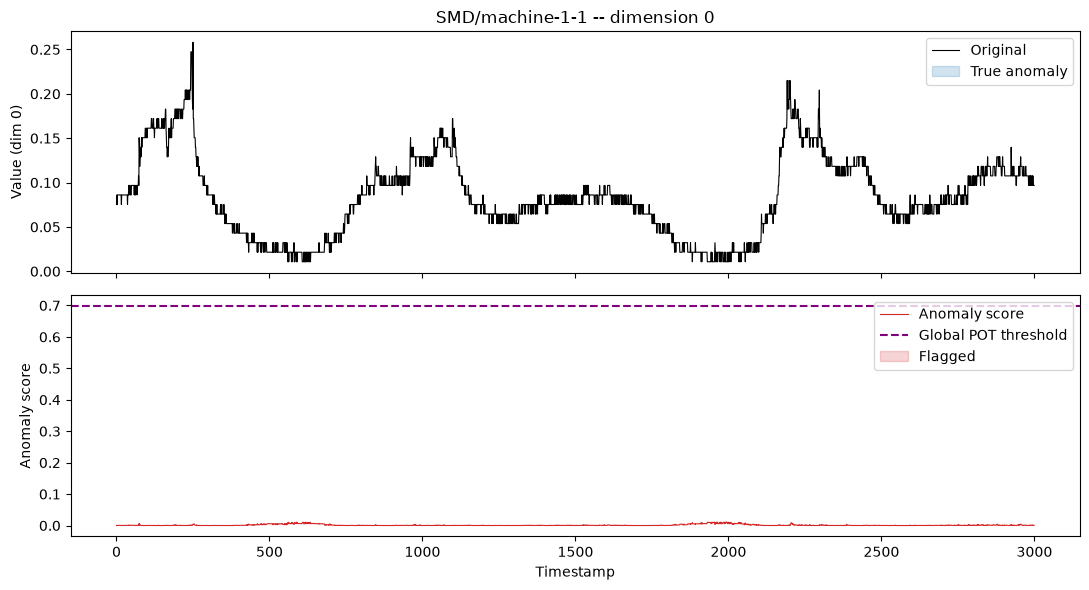

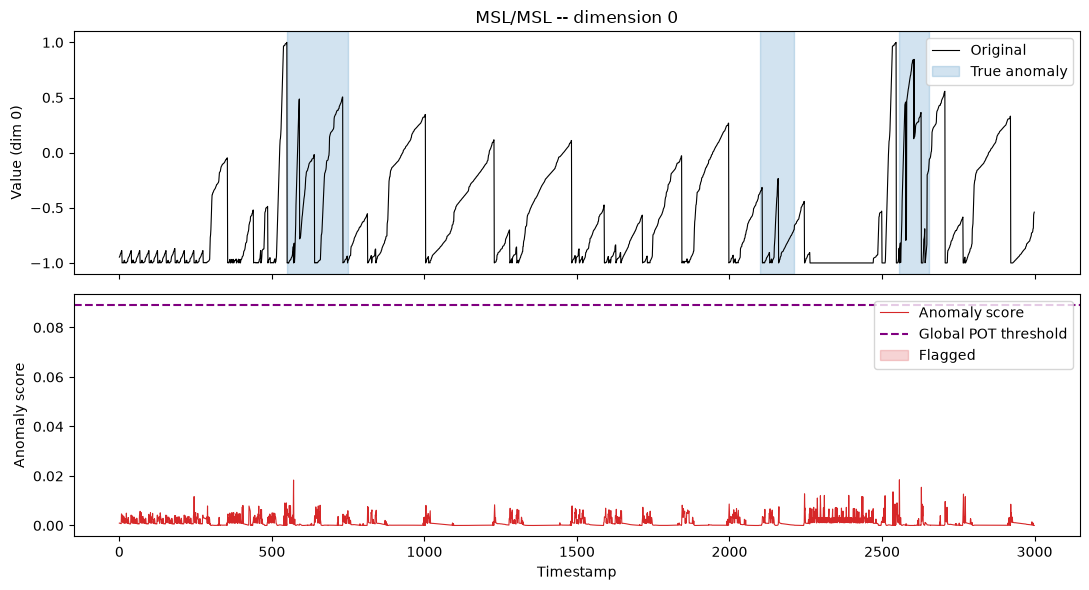

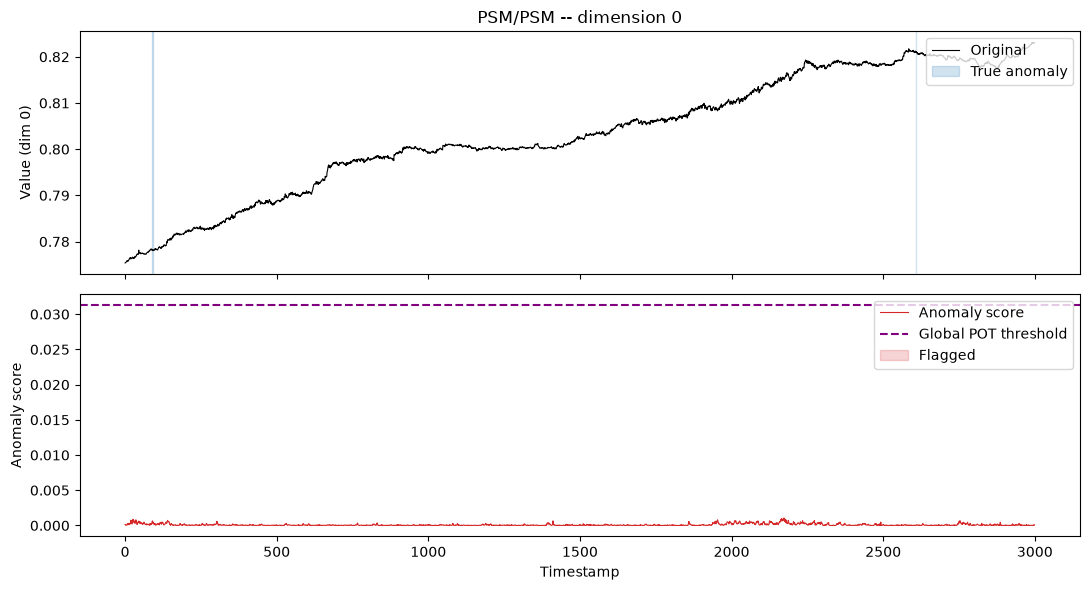

In [19]:
DIM_TO_PLOT = 0

for dataset, entity_name in DATASET_ENTITIES.items():
    arrays = RESULTS[dataset]["arrays"]
    entity_ = arrays["entity"]
    N_POINTS = min(3000, arrays["test_score"].shape[0])
    score_ = arrays["test_score"][:N_POINTS, DIM_TO_PLOT]
    labels_ = entity_.test_labels[:N_POINTS]
    threshold_ = arrays["threshold"]

    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

    axes[0].plot(entity_.test_raw[:N_POINTS, DIM_TO_PLOT], color="black", linewidth=0.8, label="Original")
    axes[0].fill_between(np.arange(N_POINTS), 0, 1, where=labels_.astype(bool),
                          transform=axes[0].get_xaxis_transform(), color="tab:blue", alpha=0.2, label="True anomaly")
    axes[0].set_ylabel(f"Value (dim {DIM_TO_PLOT})")
    axes[0].legend(loc="upper right")
    axes[0].set_title(f"{entity_.dataset}/{entity_.name} -- dimension {DIM_TO_PLOT}")

    axes[1].plot(score_, color="tab:red", linewidth=0.8, label="Anomaly score")
    axes[1].axhline(threshold_, color="purple", linestyle="--", label="Global POT threshold")
    axes[1].fill_between(np.arange(N_POINTS), 0, 1, where=(score_ >= threshold_),
                          transform=axes[1].get_xaxis_transform(), color="tab:red", alpha=0.2, label="Flagged")
    axes[1].set_ylabel("Anomaly score")
    axes[1].set_xlabel("Timestamp")
    axes[1].legend(loc="upper right")

    plt.tight_layout()
    plt.show()

### Ablation study (Table 4) — CANets / Transformer / Anomaly Feature Knowledge

Run independently per dataset; `ABLATION_RESULTS[dataset]` holds that dataset's own
four-row Table 4 (CANets-only / Transformer+Knowledge / no-Knowledge / full TEP).

In [20]:
ABLATION_RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    print(f"\n===== Ablation study (Table 4) -- {dataset} ({entity_name}) =====")
    ABLATION_RESULTS[dataset] = run_ablation_study(cfg, entity_name, data_root=DATA_ROOT, device=DEVICE, seed=0)
    print(ABLATION_RESULTS[dataset])

ABLATION_RESULTS  # {"SMD": df, "MSL": df, "PSM": df} -- independent of each other


===== Ablation study (Table 4) -- SMD (machine-1-1) =====
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.034825
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001601
[ablation CANets=True Transformer=False Knowledge=False] predicted positive rate: 0.0323  | true positive rate: 0.0946
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.033221
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.006722
[ablation CANets=False Transformer=True Knowledge=True] predicted positive rate: 0.0088  | true positive rate: 0.0946
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.034825
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001601
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.038214
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.007472
[ablation CANets=True Transformer=True Knowledge=False] predicted positi

{'SMD':    CANets  Transformer  Knowledge  precision    recall        f1       auc  \
 0    True        False      False   0.792617  0.270973  0.403873  0.809544   
 1   False         True       True   0.888889  0.083148  0.152071  0.848197   
 2    True         True      False   0.394448  0.226800  0.288004  0.836515   
 3    True         True       True   0.226554  0.079807  0.118035  0.837969   
 
         entity dataset  
 0  machine-1-1     SMD  
 1  machine-1-1     SMD  
 2  machine-1-1     SMD  
 3  machine-1-1     SMD  ,
 'MSL':    CANets  Transformer  Knowledge  precision    recall        f1       auc  \
 0    True        False      False   0.247264  0.107649  0.149996  0.580108   
 1   False         True       True   0.142256  0.047901  0.071669  0.517910   
 2    True         True      False   0.148320  0.053438  0.078569  0.476049   
 3    True         True       True   0.149889  0.052150  0.077379  0.475309   
 
   entity dataset  
 0    MSL     MSL  
 1    MSL     MSL  
 

### Section 8 demo — CANets kernel visualization (Fig. 5)

Each dataset trains its own CANets on its own windows (not the model already trained inside
`RESULTS[dataset]`, so this cell stays self-contained regardless of run order). Kernel
heatmaps are therefore never mixed across datasets; `KERNEL_MODELS[dataset]` keeps that
dataset's own `(Entity, CANets)` pair.

[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.039578
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001634


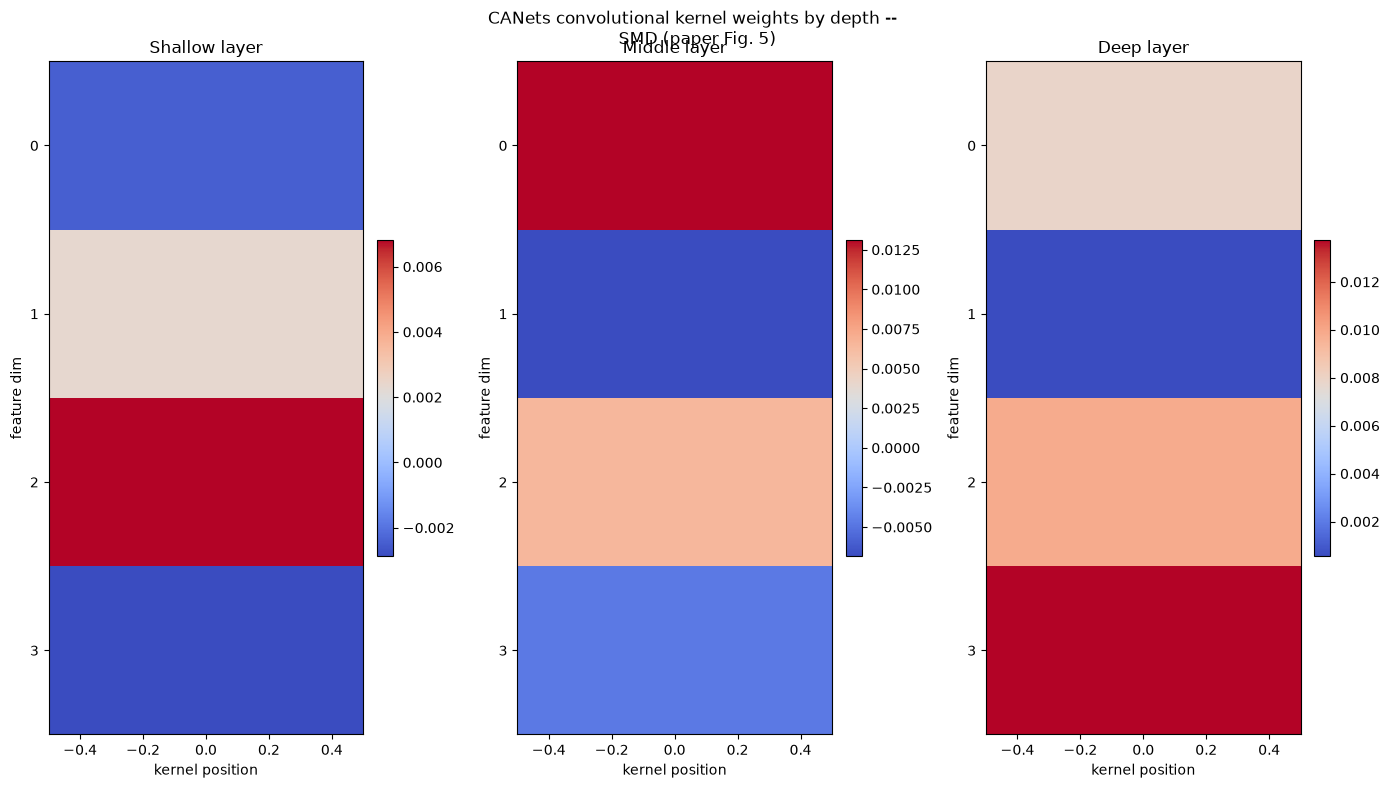

[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.028355
[CANets pretrain/MSL] epoch 5/5 loss=0.000375


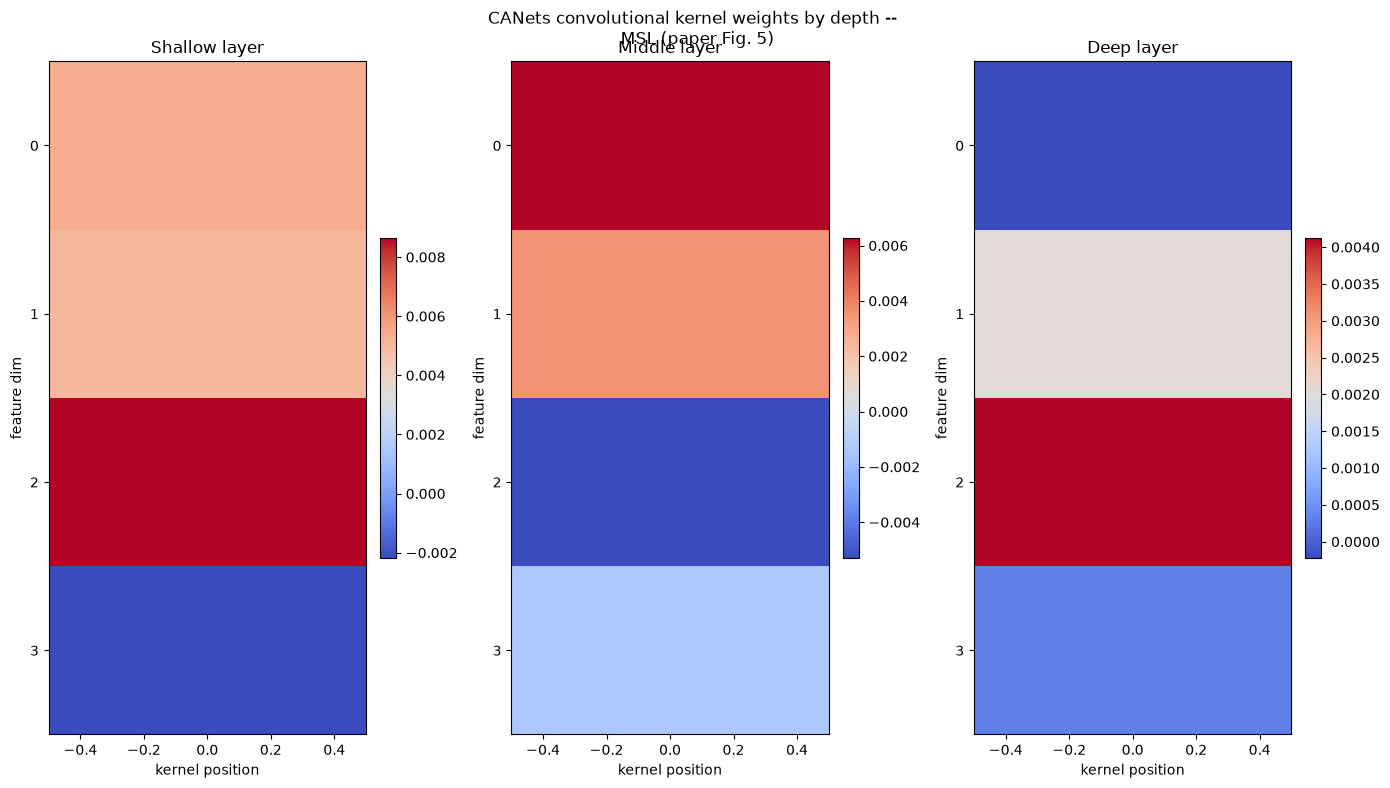

[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.005664
[CANets pretrain/PSM] epoch 5/5 loss=0.000412


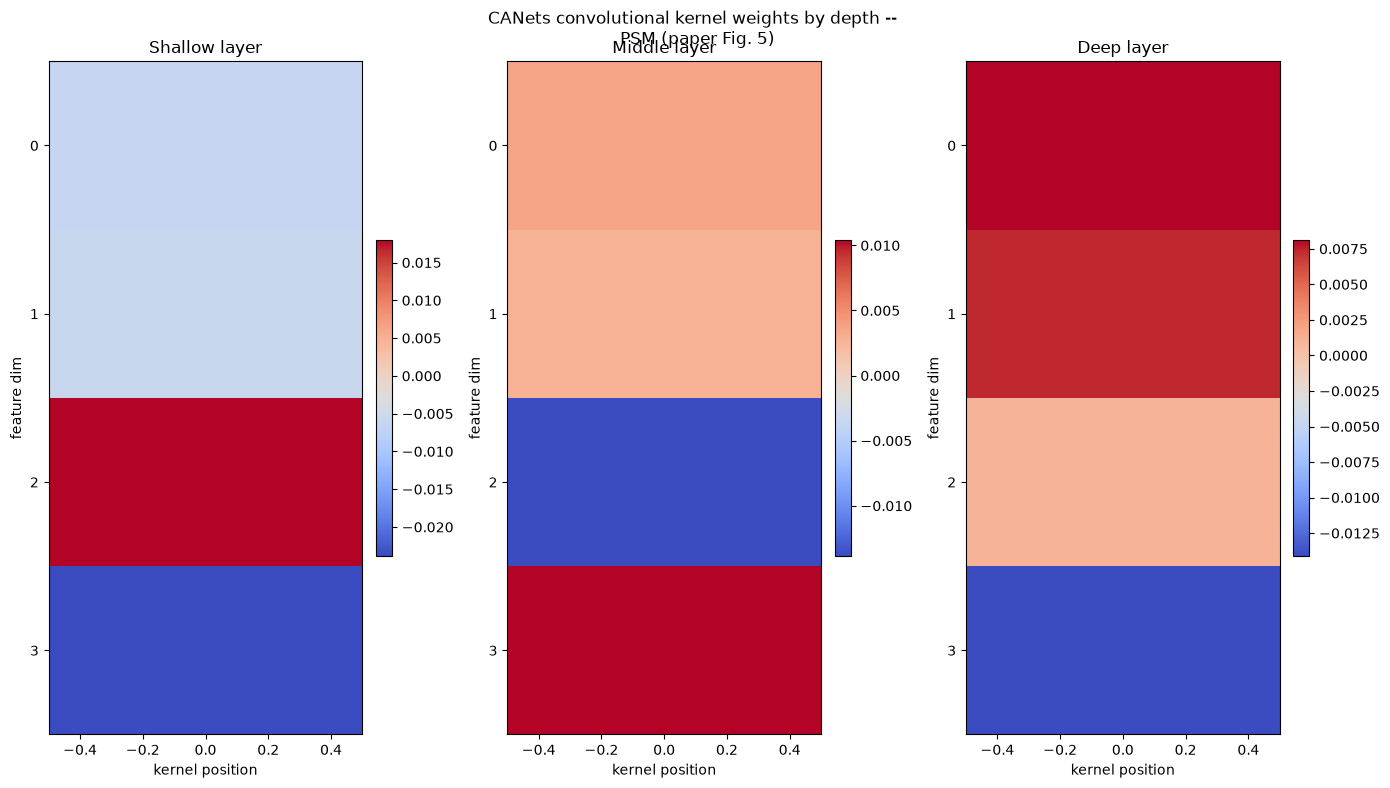

In [21]:
KERNEL_MODELS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    entity_kv, train_windows_kv, _ = prepare_entity(cfg, entity_name, DATA_ROOT)
    canets_kv = pretrain_canets(entity_kv, train_windows_kv, cfg, DEVICE)
    KERNEL_MODELS[dataset] = (entity_kv, canets_kv)

    fig_kernels = plot_conv_kernel_heatmaps(canets_kv, dims_to_plot=[0, 1, 2, 3])
    fig_kernels.suptitle(f"CANets convolutional kernel weights by depth -- \n {dataset} (paper Fig. 5)")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

### Section 9 demo — parameter sensitivity sweep (Fig. 7)

Full paper ranges are `N in {1,2,3}`, `num_layers in {1,...,5}`, `L in {0,40,70,100,150}`. The
demo below uses a reduced grid (`QUICK_TEST`) purely so the whole notebook still runs
quickly; widen the value lists for a paper-faithful sweep. Each dataset is swept starting
from its OWN `DEMO_CFGS[dataset]` (own `M`, own default `L`), so e.g. SMD's `L`-sweep and
MSL's `L`-sweep never share a config.



 ===== Parameter sensitivity sweep -- SMD (machine-1-1) ===== 
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.047537
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001653
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.033935
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.006623
[SMD/machine-1-1] predicted positive rate: 0.0079  | true positive rate: 0.0946  | POT threshold: 0.709139
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.038865
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001575
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.030409
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.005762
[SMD/machine-1-1] predicted positive rate: 0.0275  | true positive rate: 0.0946  | POT threshold: 0.654812
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.040437
[CANets pretrain/machine-1-1] epoch

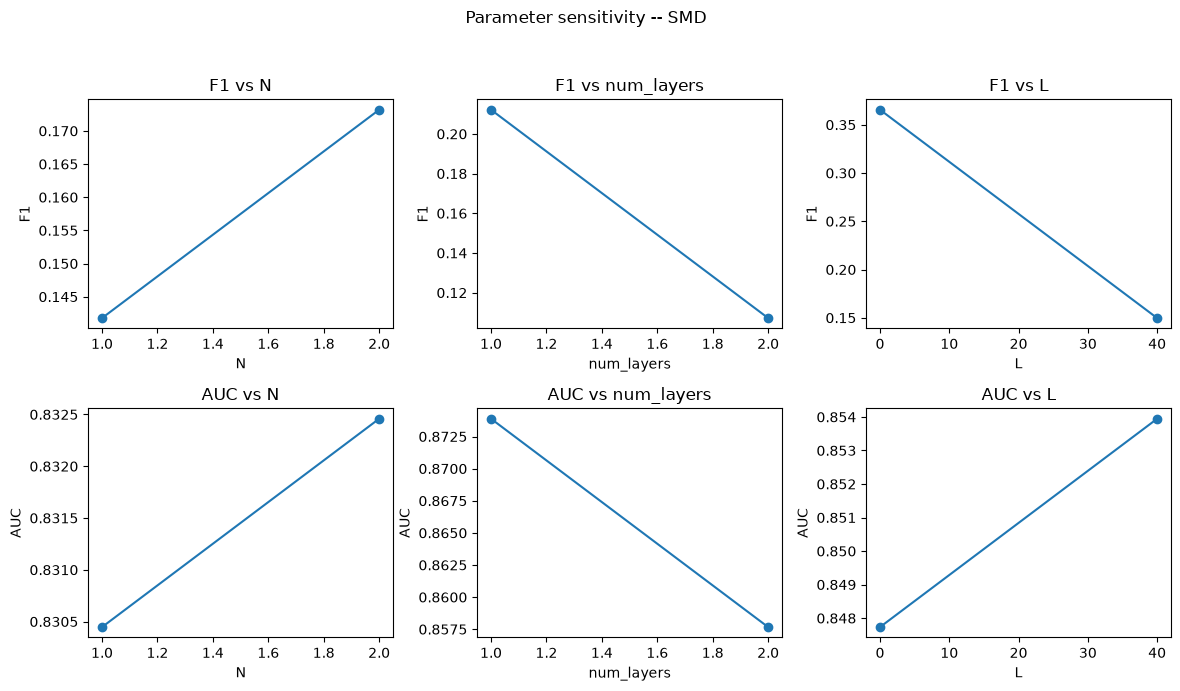



 ===== Parameter sensitivity sweep -- MSL (MSL) ===== 
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.028911
[CANets pretrain/MSL] epoch 5/5 loss=0.000728
[Reconstruction train/MSL] epoch 1/2 loss=0.030320
[Reconstruction train/MSL] epoch 2/2 loss=0.003347
[MSL/MSL] predicted positive rate: 0.0395  | true positive rate: 0.1053  | POT threshold: 0.088069
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.027549
[CANets pretrain/MSL] epoch 5/5 loss=0.000401
[Reconstruction train/MSL] epoch 1/2 loss=0.031211
[Reconstruction train/MSL] epoch 2/2 loss=0.003355
[MSL/MSL] predicted positive rate: 0.0367  | true positive rate: 0.1053  | POT threshold: 0.107131
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.029254
[CANets pretrain/MSL] epoch 5/5 loss=0.000390
[Reconstruction train/MSL] epoch 1/2 loss=0.038295
[Reconstruction train/MSL] epoch 2/2 loss=0.005154
[MSL/MS

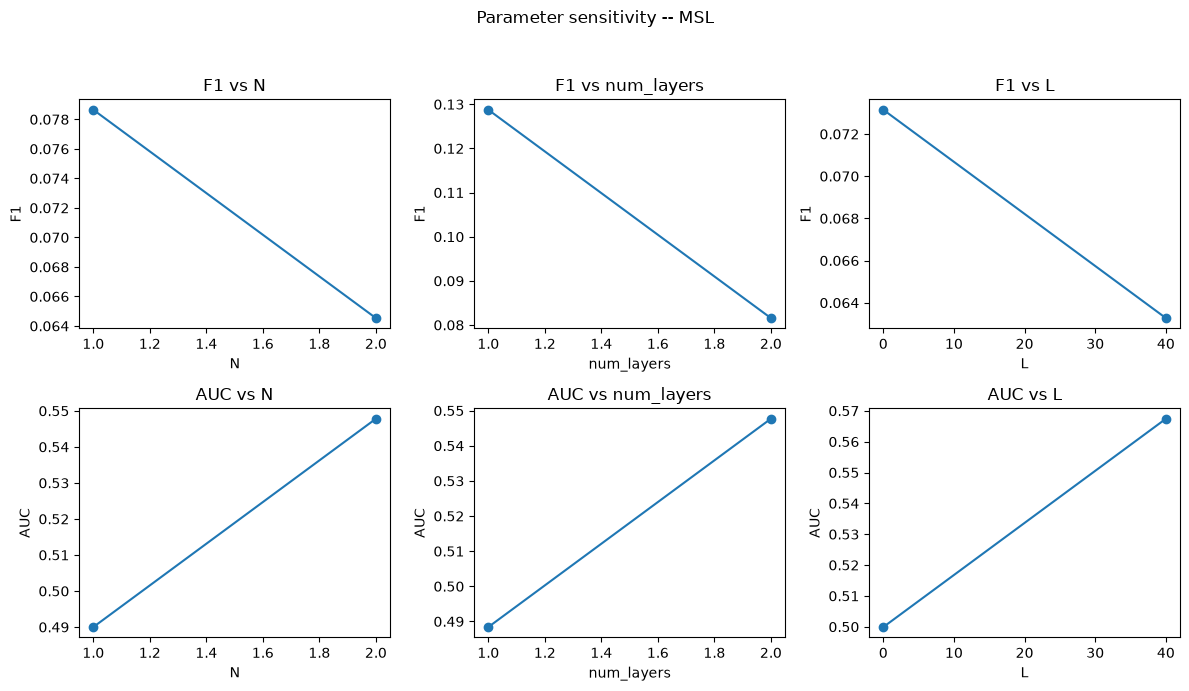



 ===== Parameter sensitivity sweep -- PSM (PSM) ===== 
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.008023
[CANets pretrain/PSM] epoch 5/5 loss=0.000460
[Reconstruction train/PSM] epoch 1/2 loss=0.005533
[Reconstruction train/PSM] epoch 2/2 loss=0.000960
[PSM/PSM] predicted positive rate: 0.0147  | true positive rate: 0.2776  | POT threshold: 0.027915
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.006609
[CANets pretrain/PSM] epoch 5/5 loss=0.000410
[Reconstruction train/PSM] epoch 1/2 loss=0.004193
[Reconstruction train/PSM] epoch 2/2 loss=0.000775
[PSM/PSM] predicted positive rate: 0.0100  | true positive rate: 0.2776  | POT threshold: 0.023664
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.006652
[CANets pretrain/PSM] epoch 5/5 loss=0.000426
[Reconstruction train/PSM] epoch 1/2 loss=0.007773
[Reconstruction train/PSM] epoch 2/2 loss=0.001098
[PSM/PS

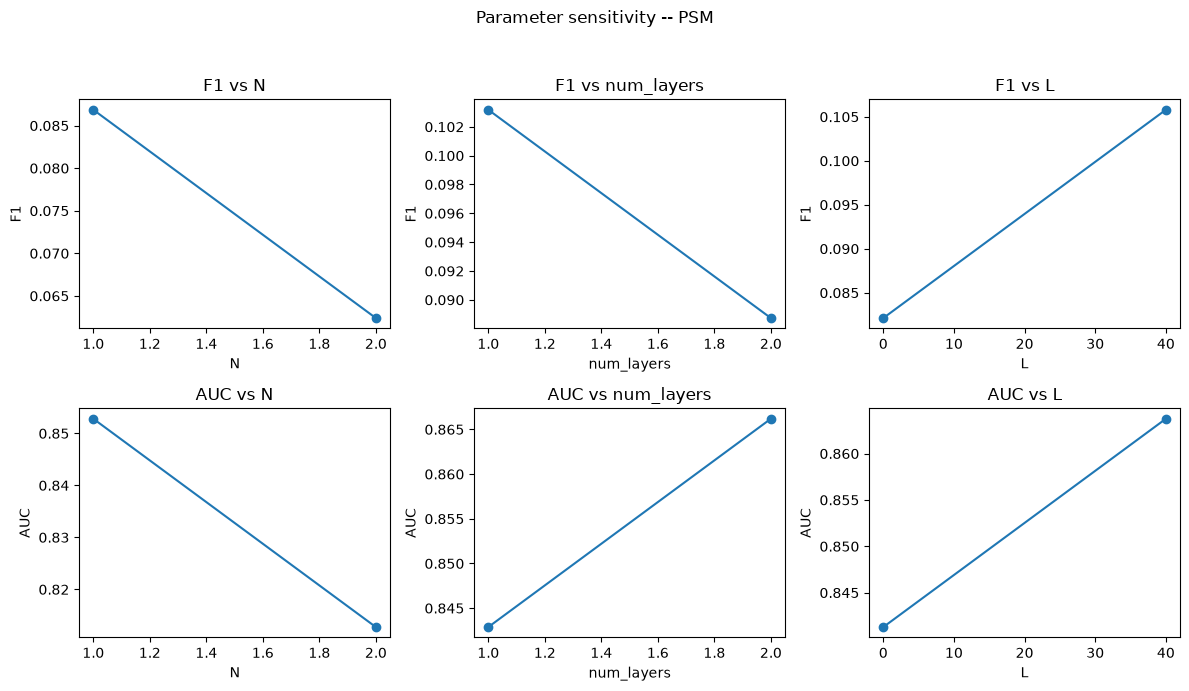

In [22]:
N_VALUES = [1, 2] if QUICK_TEST else [1, 2, 3]
NUM_LAYERS_VALUES = [1, 2] if QUICK_TEST else [1, 2, 3, 4, 5]
L_VALUES = [0, 40] if QUICK_TEST else [0, 40, 70, 100, 150]

SENSITIVITY_RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    print(f"\n\n ===== Parameter sensitivity sweep -- {dataset} ({entity_name}) ===== ")
    SENSITIVITY_RESULTS[dataset] = parameter_sensitivity_study( 
        cfg, entity_name, N_values=N_VALUES, num_layers_values=NUM_LAYERS_VALUES,
        L_values=L_VALUES, data_root=DATA_ROOT, device=DEVICE,
    )
    fig_sens = plot_sensitivity_results(SENSITIVITY_RESULTS[dataset])
    fig_sens.suptitle(f" Parameter sensitivity -- {dataset} ")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

### Section 10 demo — Gaussian-noise robustness study (Fig. 8, Fig. 9)

Paper range: SNR from 10 dB to 100 dB. Demo uses two SNR levels per dataset for speed. Each
dataset's noise is added only to that dataset's OWN training split, and its pipeline is
retrained on that noisy data -- `ROBUSTNESS_RESULTS[dataset]` never mixes another dataset's
noisy runs.

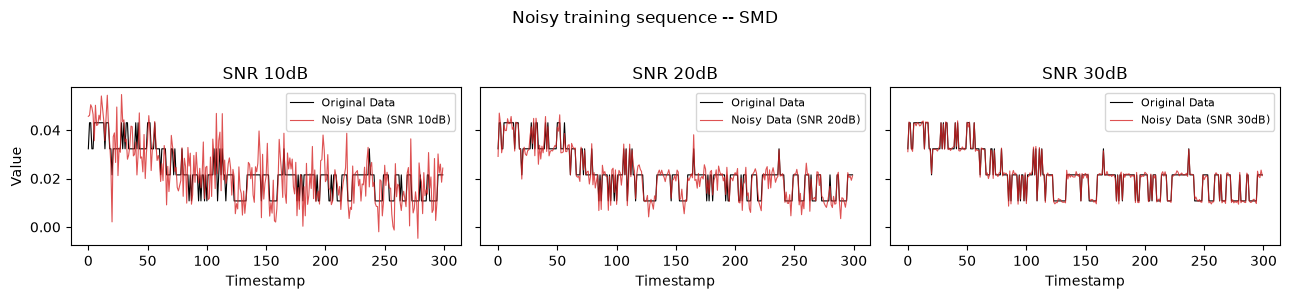


===== Robustness study -- SMD (machine-1-1) ===== 
 
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.043064
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.008646
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.046298
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.015064
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.034835
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001609
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.038221
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.007479


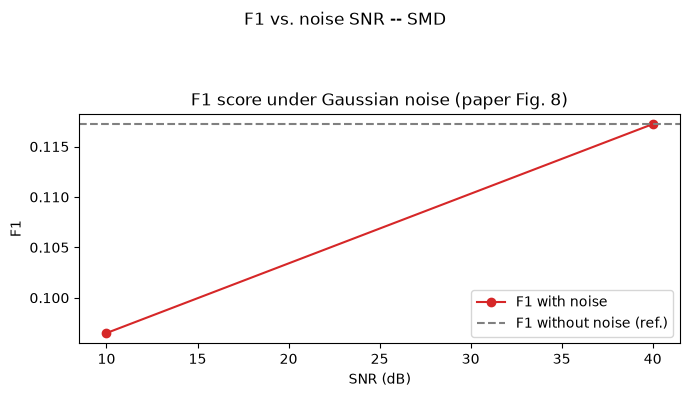

   precision    recall        f1       auc  snr_db       entity dataset
0   0.201176  0.063474  0.096501  0.828592      10  machine-1-1     SMD
1   0.226596  0.079065  0.117226  0.837997      40  machine-1-1     SMD


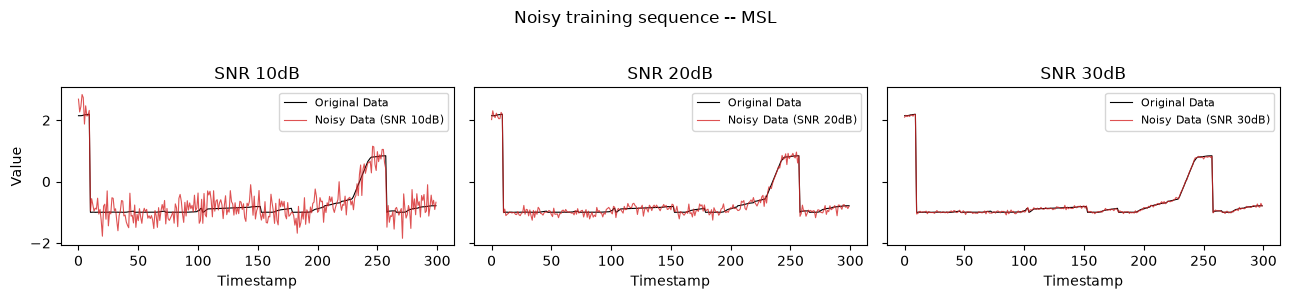


===== Robustness study -- MSL (MSL) ===== 
 
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.029297
[CANets pretrain/MSL] epoch 5/5 loss=0.000981
[Reconstruction train/MSL] epoch 1/2 loss=0.031246
[Reconstruction train/MSL] epoch 2/2 loss=0.004035
[data] loaded real data for MSL/MSL from ./data_TEP
[CANets pretrain/MSL] epoch 1/5 loss=0.028686
[CANets pretrain/MSL] epoch 5/5 loss=0.000385
[Reconstruction train/MSL] epoch 1/2 loss=0.030558
[Reconstruction train/MSL] epoch 2/2 loss=0.003386


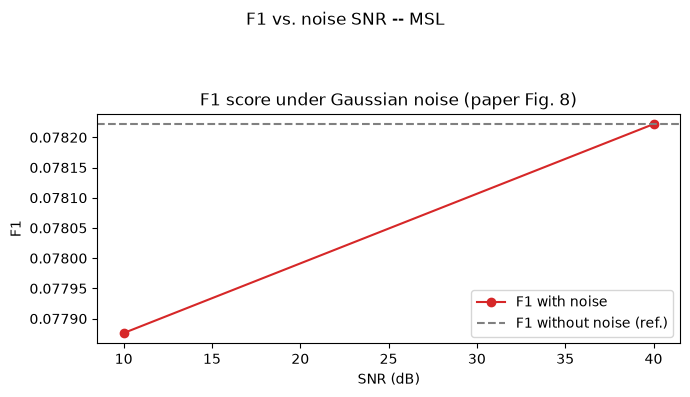

   precision    recall        f1       auc  snr_db entity dataset
0   0.140788  0.053824  0.077876  0.471489      10    MSL     MSL
1   0.150902  0.052794  0.078222  0.475294      40    MSL     MSL


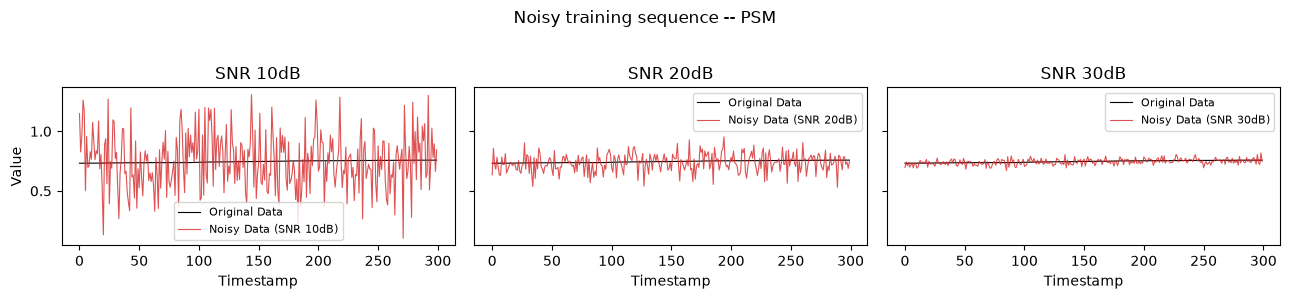


===== Robustness study -- PSM (PSM) ===== 
 
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.025012
[CANets pretrain/PSM] epoch 5/5 loss=0.004354
[Reconstruction train/PSM] epoch 1/2 loss=0.017762
[Reconstruction train/PSM] epoch 2/2 loss=0.004886
[data] loaded real data for PSM/PSM from ./data_TEP
[CANets pretrain/PSM] epoch 1/5 loss=0.006960
[CANets pretrain/PSM] epoch 5/5 loss=0.000439
[Reconstruction train/PSM] epoch 1/2 loss=0.005130
[Reconstruction train/PSM] epoch 2/2 loss=0.000966


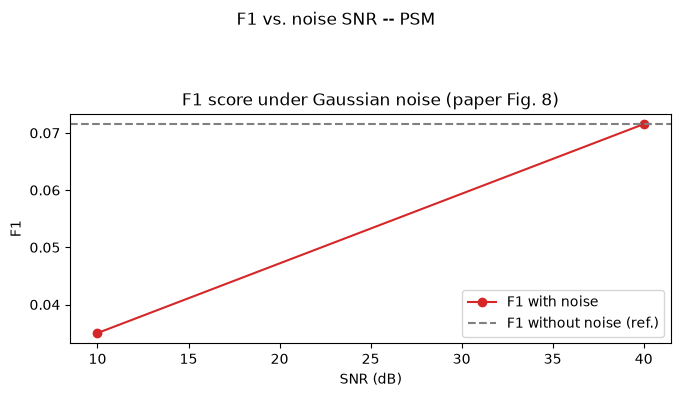

   precision    recall        f1       auc  snr_db entity dataset
0   0.195010  0.019236  0.035018  0.413222      10    PSM     PSM
1   0.857681  0.037324  0.071535  0.857078      40    PSM     PSM


In [23]:
SNR_VALUES = [10, 40] if QUICK_TEST else [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

ROBUSTNESS_RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    entity_kv, _ = KERNEL_MODELS[dataset]  # reuse the Entity already loaded for this dataset

    fig_noisy_seq = plot_noisy_sequence(entity_kv, dim=0, snr_values_db=[10, 20, 30])
    fig_noisy_seq.suptitle(f"Noisy training sequence -- {dataset}")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

    print(f"\n===== Robustness study -- {dataset} ({entity_name}) ===== \n ")
    df_rob = robustness_study(cfg, entity_name, SNR_VALUES, data_root=DATA_ROOT, device=DEVICE, seed=0)
    ROBUSTNESS_RESULTS[dataset] = df_rob

    fig_rob = plot_robustness_curve(df_rob, metric="f1")
    fig_rob.suptitle(f" F1 vs. noise SNR -- {dataset} \n")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()
    print(df_rob)

### Section 11 demo — Anomaly Feature Knowledge generalizes to TranADLite (Table 3)

See `TranADLite`'s docstring (Section 3-4) for exactly how it simplifies the real TranAD [23].
Run once per dataset; `GENERALIZATION_RESULTS[dataset]` holds that dataset's own
TranADLite-vs-TranADLite+Knowledge comparison, using that dataset's own `L`
(70 / 70 / 40 for PSM / MSL / SMD per Section 5.2).

In [24]:
GENERALIZATION_RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    print(f"\n===== Knowledge generalization to TranADLite (Table 3) -- {dataset} ({entity_name}) =====")
    GENERALIZATION_RESULTS[dataset] = knowledge_generalization_study(
        cfg, entity_name, data_root=DATA_ROOT, device=DEVICE, seed=0
    )
    print(GENERALIZATION_RESULTS[dataset])


===== Knowledge generalization to TranADLite (Table 3) -- SMD (machine-1-1) =====
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[TranADLite train/machine-1-1] epoch 1/2 loss=0.072214
[TranADLite train/machine-1-1] epoch 2/2 loss=0.025188
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[TranADLite train/machine-1-1] epoch 1/2 loss=0.072214
[TranADLite train/machine-1-1] epoch 2/2 loss=0.025188
                      method  precision    recall        f1       auc  \
0                 TranADLite   0.925000  0.013734  0.027067  0.805107   
1  TranADLite with Knowledge   0.895833  0.015961  0.031364  0.817402   

        entity dataset  
0  machine-1-1     SMD  
1  machine-1-1     SMD  

===== Knowledge generalization to TranADLite (Table 3) -- MSL (MSL) =====
[data] loaded real data for MSL/MSL from ./data_TEP
[TranADLite train/MSL] epoch 1/2 loss=0.063815
[TranADLite train/MSL] epoch 2/2 loss=0.011092
[data] loaded real data for MSL/MSL from ./data_TEP
[TranADLi

### Scaling to all 28 SMD machines / MSL / PSM, and averaging over seeds

Each entity is fully independent (Rule 1), so `run_all_entities` just loops `run_pipeline`
per entity and collects a `DataFrame` -- pass it a full SMD machine-name list to score all 28
machines separately. `SEED_RESULTS[dataset]` instead averages the single chosen entity above
over several seeds, independently per dataset (`TEPConfig.for_dataset(...)` / `.with_(...)`
lets you reuse a dataset's `M`/`L` while overriding epoch counts).

In [25]:
SEED_RESULTS = {}

for dataset, entity_name in DATASET_ENTITIES.items():
    cfg = DEMO_CFGS[dataset]
    SEED_RESULTS[dataset] = run_pipeline_multi_seed(
        cfg, entity_name, seeds=[0, 1, 2], data_root=DATA_ROOT, device=DEVICE,
    )

SEED_RESULTS  # {"SMD": df, "MSL": df, "PSM": df} -- independent of each other

[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.034825
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001601
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.038214
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.007472
[SMD/machine-1-1] predicted positive rate: 0.0333  | true positive rate: 0.0946  | POT threshold: 0.698078
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.039696
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001692
[Reconstruction train/machine-1-1] epoch 1/2 loss=0.037357
[Reconstruction train/machine-1-1] epoch 2/2 loss=0.007122
[SMD/machine-1-1] predicted positive rate: 0.0269  | true positive rate: 0.0946  | POT threshold: 0.708175
[data] loaded real data for SMD/machine-1-1 from ./data_TEP
[CANets pretrain/machine-1-1] epoch 1/5 loss=0.032484
[CANets pretrain/machine-1-1] epoch 5/5 loss=0.001594
[Reconstruction train/machine-1-1] epoch 1/2 l

{'SMD':    precision    recall        f1       auc  blind_precision  blind_recall  \
 0   0.226554  0.079807  0.118035  0.837969         0.171647           1.0   
 1   0.265359  0.075353  0.117375  0.838070         0.172958           1.0   
 2   0.446738  0.200817  0.277081  0.811975         0.167569           1.0   
 
    blind_f1  blind_auc       entity dataset  seed  
 0  0.293001   0.710807  machine-1-1     SMD     0  
 1  0.294910   0.710988  machine-1-1     SMD     1  
 2  0.287039   0.664156  machine-1-1     SMD     2  ,
 'MSL':    precision    recall        f1       auc  blind_precision  blind_recall  \
 0   0.149889  0.052150  0.077379  0.475309         0.112916      0.041954   
 1   0.152132  0.070306  0.096169  0.500365         0.115972      0.065517   
 2   0.167774  0.039016  0.063310  0.478378         0.151456      0.044828   
 
    blind_f1  blind_auc entity dataset  seed  
 0  0.061177   0.490012    MSL     MSL     0  
 1  0.083731   0.489187    MSL     MSL     1  
 2  

## Where the paper is ambiguous or silent — what we assumed, and why

The paper is not fully self-consistent (e.g. its own Table 2 and Section 5.1 text disagree on
SMD's size), and it leaves several implementation details without a concrete value. Every
place this happens is marked `PAPER GAP` inline in the code above; the main ones:

1. **TCEBlock LayerNorms.** Eq. (10)'s residual formulas write `I0 + MultiHeadAtt(...)` and
   `I2 + Linear(LReLU(Linear(I2)))` with no LayerNorm term, but Fig. 2's block diagram shows
   explicit "Add & Norm" boxes around both steps. We keep LayerNorm (matching Fig. 2 and
   standard Transformer/Conformer practice) — the paper's own equations and figure disagree
   here, and we picked the figure.
2. **Conv kernel sizes in TCEBlock.** Only the upsampling conv's kernel (`k - 1`) is ever given
   a numeric value. The projection layer and downsampling layer never get one; `TCEBlock` now
   exposes `proj_kernel_size` / `down_kernel_size` as explicit constructor arguments (default 1,
   pointwise), since the paper describes them as reshaping/aggregating steps, not additional
   temporal mixing.
3. **POT risk level `q` (Eq. 21).** Never given a numeric value in the paper. `TEPConfig.pot_risk`
   defaults to `1e-3`, a common choice in this line of work (OmniAnomaly, TranAD, Anomaly
   Transformer); treat it as a tunable hyperparameter, not a paper-specified constant.
4. **Threshold calibrated on the test set itself.** Algorithm 3 takes only the test series as
   input, so `delta` is fit on the very data it then scores — this is the paper's own procedure,
   not ours, but it makes the plain F1 in `run_pipeline` optimistic. Use `F1_blind` (Section 6)
   for a less biased estimate.
5. **`TranADLite` (Section 11 / Table 3) is a deliberately simplified stand-in for the real
   TranAD [23]**, which uses two-phase adversarial training with two decoders. `TranADLite` is
   a single-phase Transformer encoder/decoder autoencoder — it keeps only the property Section
   5.5 actually needs (an independent, non-CANets reconstruction model to test whether Anomaly
   Feature Knowledge helps something other than TEP), not a literal reproduction of TranAD's
   architecture or training procedure.

6. **`R_error` in Eq. (18) vs. Algorithm 3's windowing.** Eq. (18) defines `R_error` as a
   single scalar -- the MSE averaged over *all* `T'` timestamps and `M` dimensions at once.
   But Algorithm 3 immediately partitions that same `R_error` with a sliding window into
   `T'` per-timestamp windows `{S_1, ..., S_{T'}}` (Eq. 19) -- which only makes sense if
   `R_error` is itself a per-`(t, dim)` array, not a scalar. The paper never resolves this:
   a single number cannot be "sliding-windowed" into `T'` separate pieces. We implement
   `R_error` as the elementwise squared error `|X_hat - X|^2`, kept at shape `(T', M)`
   (never reduced to a scalar), since that is the only interpretation Algorithm 3's own
   pseudocode can actually run on; Eq. (18)'s scalar-mean notation is treated as describing
   the *training loss* (Eq. 17), not the per-point array consumed at decision time. See the
   `PAPER GAP` comment on `compute_reconstruction_errors` in Section 7.

7. **`PositionalEncoding` bug on odd `M` (found while adding independent MSL/PSM runs).**
   `pe[:, 1::2] = cos(...)` used the full `div_term`, which is one element too long whenever
   `embed_dim` is odd -- true for `TranADLite`'s `PositionalEncoding(cfg.M)` on MSL (`M=55`) and
   PSM (`M=25`), both odd. `CANets`/`ReconstructionTransformer` always use `embed_dim = 2*M`
   (even), so this was invisible in the original SMD-only demo cells. Fixed by truncating
   `div_term` to the cosine slice's actual width; see the fix note on `PositionalEncoding`
   (Section 2).

Nothing above is silent in the code — each point is called out again, in more detail, at the
exact line where it's decided (`PAPER GAP` comments in Sections 0-11 above).